SMART SHELF AI IVP

DRIVE AND GITHUB REPOSITORY SETUP

In [5]:
# Step 1: Clone our new GitHub repository into Colab

from pathlib import Path
import subprocess

# URL of our newly created GitHub repository
REPO_URL = "https://github.com/kasheeesh08/smart-shelf-ai.git"

# Local folder where the new repository will be stored in Colab
REPO_DIR = Path("/content/smart-shelf-ai")

# Clone only if the folder does not already exist
if not REPO_DIR.exists():
    result = subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        capture_output=True,
        text=True
    )

    # Stop if GitHub cloning fails
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Repository cloning failed.")

    print("New repository cloned successfully.")
else:
    print("Repository folder already exists.")

# Verify that Git is connected to the correct repository
def git(*args):
    return subprocess.run(
        ["git", "-C", str(REPO_DIR), *args],
        capture_output=True,
        text=True
    )

print("Repository folder:", REPO_DIR)
print("GitHub remote:", git("remote", "get-url", "origin").stdout.strip())
print("Current branch:", git("branch", "--show-current").stdout.strip())
print("Git status:", git("status", "--short").stdout.strip() or "Clean")


Repository folder already exists.
Repository folder: /content/smart-shelf-ai
GitHub remote: https://github.com/kasheeesh08/smart-shelf-ai.git
Current branch: main
Git status: Clean


In [6]:

# Step 2: Mount Google Drive and inspect Smart Shelf AI files

from pathlib import Path

# Mount Google Drive only if it is not already accessible
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

# Verify that Google Drive is accessible before continuing
DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.exists():
    raise RuntimeError(
        "Google Drive is not accessible. Complete the authorization prompt and rerun this cell."
    )

print("Google Drive is accessible.")

# Set the folder containing our existing Smart Shelf AI project files
DRIVE_PROJECT = DRIVE_ROOT / "product-identification-correlation_data"

# List important project files and folders to check
PROJECT_PATHS = [
    "roboflow_v3_yolov8",
    "smart_shelf_deployment",
    "smart_shelf_app",
    "final_detection_audit",
    "results",
    "retail_intelligence",
    "visual_error_report",
    "verified_overall_metrics.csv",
    "verified_per_class_metrics.csv",
    "verified_per_image_metrics.csv",
    "verified_error_diagnostics.csv",
    "per_class_model_comparison.csv",
    "smart_shelf_research_package.zip",
    "smart_shelf_deployment.zip",
]

# Check which project items are available without modifying anything
if not DRIVE_PROJECT.exists():
    print(f"\nProject folder not found: {DRIVE_PROJECT}")
    print("Please check the folder name in Google Drive before proceeding.")
else:
    print(f"\nProject folder found: {DRIVE_PROJECT}")
    print("\nProject inventory:")

    for item in PROJECT_PATHS:
        path = DRIVE_PROJECT / item

        if path.exists():
            item_type = "Folder" if path.is_dir() else "File"
            print(f"[FOUND]   {item_type}: {item}")
        else:
            print(f"[MISSING] {item}")

# Confirm the new GitHub repository is still available locally
REPO_DIR = Path("/content/smart-shelf-ai")
if REPO_DIR.exists():
    print("\nNew GitHub repository folder is available.")
else:
    print("\nNew GitHub repository folder is missing; stop before copying files.")


Mounted at /content/drive
Google Drive is accessible.

Project folder found: /content/drive/MyDrive/product-identification-correlation_data

Project inventory:
[FOUND]   Folder: roboflow_v3_yolov8
[FOUND]   Folder: smart_shelf_deployment
[FOUND]   Folder: smart_shelf_app
[FOUND]   Folder: final_detection_audit
[FOUND]   Folder: results
[FOUND]   Folder: retail_intelligence
[FOUND]   Folder: visual_error_report
[FOUND]   File: verified_overall_metrics.csv
[FOUND]   File: verified_per_class_metrics.csv
[FOUND]   File: verified_per_image_metrics.csv
[FOUND]   File: verified_error_diagnostics.csv
[FOUND]   File: per_class_model_comparison.csv
[FOUND]   File: smart_shelf_research_package.zip
[FOUND]   File: smart_shelf_deployment.zip

New GitHub repository folder is available.


In [7]:

# Step 3: Inspect the existing Smart Shelf AI project files

from pathlib import Path

# Define the verified Google Drive project and new GitHub repository
DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)
REPO_DIR = Path("/content/smart-shelf-ai")

# Verify that both locations are available before inspecting files
assert DRIVE_PROJECT.is_dir(), "Google Drive project folder is missing."
assert REPO_DIR.is_dir(), "New GitHub repository folder is missing."

print("Source: Google Drive")
print("Destination: New smart-shelf-ai repository")
print("\nInspection only — no files will be changed.")

# Inspect the main project folders and important files
PATHS_TO_INSPECT = [
    "roboflow_v3_yolov8",
    "smart_shelf_deployment",
    "smart_shelf_app",
    "final_detection_audit",
    "results",
    "retail_intelligence",
    "visual_error_report",
    "verified_overall_metrics.csv",
    "verified_per_class_metrics.csv",
    "verified_per_image_metrics.csv",
    "verified_error_diagnostics.csv",
    "per_class_model_comparison.csv",
    "smart_shelf_research_package.zip",
    "smart_shelf_deployment.zip",
]

# Display the contents of each selected folder without scanning subfolders
for relative_path in PATHS_TO_INSPECT:
    path = DRIVE_PROJECT / relative_path
    print(f"\n{'=' * 60}")
    print(f"ITEM: {relative_path}")

    # Report missing paths without interrupting the inspection
    if not path.exists():
        print("Not found.")
        continue

    # Display the size of individual files in a readable format
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"File size: {size_mb:.2f} MB")
        continue

    # List only immediate contents to avoid scanning large datasets
    entries = sorted(path.iterdir(), key=lambda item: item.name.lower())
    print(f"Immediate items: {len(entries)}")

    for item in entries[:30]:
        if item.is_file():
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"  FILE   {item.name} ({size_mb:.2f} MB)")
        else:
            print(f"  FOLDER {item.name}/")

    # Indicate if more entries exist beyond the displayed limit
    if len(entries) > 30:
        print(f"  ... and {len(entries) - 30} more items")

# Confirm the new repository has not received any project files yet
print(f"\n{'=' * 60}")
print("New repository top-level contents:")
for item in sorted(REPO_DIR.iterdir(), key=lambda item: item.name.lower()):
    print(f"  {item.name}")

print("\nInspection complete.")


Source: Google Drive
Destination: New smart-shelf-ai repository

Inspection only — no files will be changed.

ITEM: roboflow_v3_yolov8
Immediate items: 6
  FILE   data.yaml (0.00 MB)
  FILE   data_9class.yaml (0.00 MB)
  FILE   README.roboflow.txt (0.00 MB)
  FOLDER test/
  FOLDER train/
  FOLDER valid/

ITEM: smart_shelf_deployment
Immediate items: 5
  FILE   app.py (0.00 MB)
  FILE   inference.py (0.00 MB)
  FILE   README.md (0.00 MB)
  FILE   requirements.txt (0.00 MB)
  FILE   yolov8n_9class_v3_best.pt (6.21 MB)

ITEM: smart_shelf_app
Immediate items: 6
  FOLDER __pycache__/
  FILE   app.py (0.01 MB)
  FILE   app_backup_20261021_222710.py (0.00 MB)
  FILE   inference.py (0.00 MB)
  FILE   streamlit_test.log (0.00 MB)
  FILE   streamlit_test_8502.log (0.00 MB)

ITEM: final_detection_audit
Immediate items: 4
  FILE   error_diagnostics.csv (0.00 MB)
  FILE   overall_metrics.csv (0.00 MB)
  FILE   per_class_metrics.csv (0.00 MB)
  FILE   per_image_counts.csv (0.00 MB)

ITEM: results
Im

In [8]:

# Step 4: Create a clean folder structure for Smart Shelf AI

from pathlib import Path

# Point to our new GitHub repository, not the old repository
REPO_DIR = Path("/content/smart-shelf-ai")

# Define folders to organize code, notebooks, results, and documentation
PROJECT_FOLDERS = [
    "app",
    "src",
    "notebooks",
    "results",
    "research",
]

# Confirm that we are working in the correct repository
assert REPO_DIR.is_dir(), "New repository folder not found."
assert (
    REPO_DIR / ".git"
).is_dir(), "This folder is not a Git repository."

# Create the required folders without overwriting existing files
for folder in PROJECT_FOLDERS:
    folder_path = REPO_DIR / folder
    folder_path.mkdir(parents=True, exist_ok=True)
    print(f"Ready: {folder}/")

print("\nRepository structure prepared.")
print("No Drive files were copied or modified.")


Ready: app/
Ready: src/
Ready: notebooks/
Ready: results/
Ready: research/

Repository structure prepared.
No Drive files were copied or modified.


In [10]:
# Step 5: Copy selected deployment files and evaluation results
# Existing destination files are preserved; only missing files are copied.

from pathlib import Path
import shutil

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)
REPO_DIR = Path("/content/smart-shelf-ai")

FILES_TO_COPY = {
    "smart_shelf_deployment/app.py": "app/app.py",
    "smart_shelf_deployment/inference.py": "src/inference.py",
    "smart_shelf_deployment/README.md": "app/README.md",
    "smart_shelf_deployment/requirements.txt": "app/requirements.txt",
    "smart_shelf_deployment/yolov8n_9class_v3_best.pt":
        "app/yolov8n_9class_v3_best.pt",
    "verified_overall_metrics.csv": "results/overall_metrics.csv",
    "verified_per_class_metrics.csv": "results/per_class_metrics.csv",
    "verified_per_image_metrics.csv": "results/per_image_metrics.csv",
    "verified_error_diagnostics.csv": "results/error_diagnostics.csv",
    "per_class_model_comparison.csv": "results/model_comparison.csv",
}

assert DRIVE_PROJECT.is_dir(), "Google Drive project folder not found."
assert (REPO_DIR / ".git").is_dir(), "Git repository not found."

# Validate all source files before copying.
missing_sources = [
    source for source in FILES_TO_COPY
    if not (DRIVE_PROJECT / source).is_file()
]

if missing_sources:
    raise FileNotFoundError(
        "Copy cancelled. Missing source files:\n"
        + "\n".join(missing_sources)
    )

copied, skipped = [], []

for source, destination in FILES_TO_COPY.items():
    source_path = DRIVE_PROJECT / source
    destination_path = REPO_DIR / destination

    destination_path.parent.mkdir(parents=True, exist_ok=True)

    if destination_path.exists():
        skipped.append(destination)
        print(f"SKIPPED (already exists): {destination}")
        continue

    shutil.copy2(source_path, destination_path)
    copied.append(destination)
    print(f"COPIED: {source} -> {destination}")

print("\nCopy summary")
print("New files copied:", len(copied))
print("Existing files preserved:", len(skipped))
print("No Git commit or push was performed.")


SKIPPED (already exists): app/app.py
COPIED: smart_shelf_deployment/inference.py -> src/inference.py
SKIPPED (already exists): app/README.md
SKIPPED (already exists): app/requirements.txt
SKIPPED (already exists): app/yolov8n_9class_v3_best.pt
SKIPPED (already exists): results/overall_metrics.csv
SKIPPED (already exists): results/per_class_metrics.csv
SKIPPED (already exists): results/per_image_metrics.csv
SKIPPED (already exists): results/error_diagnostics.csv
SKIPPED (already exists): results/model_comparison.csv

Copy summary
New files copied: 1
Existing files preserved: 9
No Git commit or push was performed.


In [11]:

# Step 6: Keep the app, inference code, and model in the same folder

from pathlib import Path
import shutil

# Locate the new repository
REPO_DIR = Path("/content/smart-shelf-ai")

# Define the files that need to be moved into the app folder
MOVES = {
    REPO_DIR / "src" / "inference.py":
        REPO_DIR / "app" / "inference.py",
    REPO_DIR / "app" / "yolov8n_9class_v3_best.pt":
        REPO_DIR / "app" / "yolov8n_9class_v3_best.pt",
}

# Move inference.py only if it is not already in the app folder
source = REPO_DIR / "src" / "inference.py"
destination = REPO_DIR / "app" / "inference.py"

if source.exists() and not destination.exists():
    shutil.move(str(source), str(destination))
    print("Moved inference.py into app/")

# Verify the app and its model checkpoint are together
required_files = [
    REPO_DIR / "app" / "app.py",
    REPO_DIR / "app" / "inference.py",
    REPO_DIR / "app" / "yolov8n_9class_v3_best.pt",
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(f"Required deployment file missing: {file_path}")
    print(f"Verified: {file_path.relative_to(REPO_DIR)}")

print("\nDeployment files are organized together.")


Verified: app/app.py
Verified: app/inference.py
Verified: app/yolov8n_9class_v3_best.pt

Deployment files are organized together.


In [13]:

# Step 7: Inspect the existing .gitignore file
# This cell does not modify or overwrite anything.

from pathlib import Path

REPO_DIR = Path("/content/smart-shelf-ai")
GITIGNORE_PATH = REPO_DIR / ".gitignore"

if not GITIGNORE_PATH.is_file():
    print(".gitignore does not exist yet.")
    print("You can run the original creation cell.")
else:
    print("Existing .gitignore found.")
    print("=" * 60)
    print(GITIGNORE_PATH.read_text(encoding="utf-8"))
    print("=" * 60)
    print("No changes made.")


Existing .gitignore found.
# Python cache and compiled files
__pycache__/
*.py[cod]
*.pyo

# Virtual environments
.venv/
venv/
env/

# Local environment variables and secrets
.env
.env.*
!.env.example
*.pem
*.key

# Jupyter temporary files and checkpoints
.ipynb_checkpoints/

# Logs and temporary outputs
*.log
tmp/
temp/

# Raw datasets and generated training artifacts
datasets/
runs/
train/
valid/
test/

# Operating system files
.DS_Store
Thumbs.db

No changes made.


In [15]:

# Step 8: Inspect existing project documentation and requirements
# Read-only: no files will be created or overwritten.

from pathlib import Path

REPO_DIR = Path("/content/smart-shelf-ai")

FILES_TO_INSPECT = [
    REPO_DIR / "README.md",
    REPO_DIR / "requirements.txt",
    REPO_DIR / "app" / "README.md",
    REPO_DIR / "app" / "requirements.txt",
]

for file_path in FILES_TO_INSPECT:
    print("\n" + "=" * 70)
    print(f"File: {file_path.relative_to(REPO_DIR)}")
    print("=" * 70)

    if not file_path.is_file():
        print("File does not exist.")
        continue

    content = file_path.read_text(encoding="utf-8")
    print(content[:8000])

    if len(content) > 8000:
        print("\n... Output truncated for inspection ...")

print("\nInspection complete. No files were modified.")



File: README.md
# Smart Shelf AI

Smart Shelf AI is a computer vision project for detecting and counting
nine product classes in shelf images. It uses a trained YOLOv8n model
and a Streamlit interface for image-based inference.

## Features

- Upload a shelf image through the Streamlit application.
- Detect and count supported product classes.
- Display model predictions using the inference module.
- Store evaluation summaries in CSV format.

## Project Structure

```text
smart-shelf-ai/
├── app/
│   ├── app.py
│   ├── inference.py
│   ├── requirements.txt
│   └── yolov8n_9class_v3_best.pt
├── src/
├── notebooks/
├── results/
│   ├── overall_metrics.csv
│   ├── per_class_metrics.csv
│   ├── per_image_metrics.csv
│   ├── error_diagnostics.csv
│   └── model_comparison.csv
├── research/
├── .gitignore
├── README.md
└── requirements.txt
```

## Run the Application

1. Install Python and create a virtual environment.
2. Install the application dependencies:

   ```bash
   pip install -r ap

In [16]:

# Step 9: Audit the repository before publishing it to GitHub

from pathlib import Path
import subprocess

# Locate the new GitHub repository
REPO_DIR = Path("/content/smart-shelf-ai")

# Confirm that this is the correct Git repository
assert (REPO_DIR / ".git").is_dir(), "Git repository not found."

# List all files currently inside the repository, excluding Git internals
print("=== REPOSITORY FILES ===")
for file_path in sorted(REPO_DIR.rglob("*")):
    if not file_path.is_file():
        continue

    # Skip Git's internal metadata
    if ".git" in file_path.parts:
        continue

    relative_path = file_path.relative_to(REPO_DIR)
    size_kb = file_path.stat().st_size / 1024
    print(f"{relative_path} ({size_kb:.1f} KB)")

# Check that the essential project files exist
required_files = [
    "README.md",
    ".gitignore",
    "requirements.txt",
    "app/app.py",
    "app/inference.py",
    "app/requirements.txt",
    "app/yolov8n_9class_v3_best.pt",
    "results/overall_metrics.csv",
    "results/per_class_metrics.csv",
    "results/per_image_metrics.csv",
    "results/error_diagnostics.csv",
    "results/model_comparison.csv",
]

print("\n=== REQUIRED FILE CHECK ===")
missing_files = []

for relative_path in required_files:
    exists = (REPO_DIR / relative_path).is_file()
    print(f"[{'OK' if exists else 'MISSING'}] {relative_path}")

    if not exists:
        missing_files.append(relative_path)

# Display Git's current status without staging any files
result = subprocess.run(
    ["git", "-C", str(REPO_DIR), "status", "--short", "--ignored"],
    capture_output=True,
    text=True,
    check=True,
)

print("\n=== GIT STATUS (INCLUDING IGNORED FILES) ===")
print(result.stdout.strip() or "No changes detected.")

# Report whether the repository is ready for the next review
if missing_files:
    print("\nAudit incomplete. Required files are missing.")
else:
    print("\nAll required files are present.")
    print("Review the file list before the first commit.")


=== REPOSITORY FILES ===
.gitignore (0.4 KB)
README.md (2.3 KB)
app/README.md (0.3 KB)
app/app.py (3.7 KB)
app/inference.py (2.5 KB)
app/requirements.txt (0.1 KB)
app/yolov8n_9class_v3_best.pt (6357.7 KB)
requirements.txt (0.0 KB)
results/error_diagnostics.csv (0.2 KB)
results/model_comparison.csv (1.0 KB)
results/overall_metrics.csv (0.1 KB)
results/per_class_metrics.csv (1.0 KB)
results/per_image_metrics.csv (2.4 KB)
src/inference.py (2.5 KB)

=== REQUIRED FILE CHECK ===
[OK] README.md
[OK] .gitignore
[OK] requirements.txt
[OK] app/app.py
[OK] app/inference.py
[OK] app/requirements.txt
[OK] app/yolov8n_9class_v3_best.pt
[OK] results/overall_metrics.csv
[OK] results/per_class_metrics.csv
[OK] results/per_image_metrics.csv
[OK] results/error_diagnostics.csv
[OK] results/model_comparison.csv

=== GIT STATUS (INCLUDING IGNORED FILES) ===
?? src/

All required files are present.
Review the file list before the first commit.


In [17]:

# Step 10: Stage the approved Smart Shelf AI project files
# Review the staged list before proceeding to the commit.

from pathlib import Path
import subprocess

# Locate the new GitHub repository
REPO_DIR = Path("/content/smart-shelf-ai")

# Explicitly list the files and folders approved for publication
APPROVED_PATHS = [
    ".gitignore",
    "README.md",
    "requirements.txt",
    "app/",
    "results/",
]

# Run Git commands inside the new repository
def run_git(*args):
    return subprocess.run(
        ["git", "-C", str(REPO_DIR), *args],
        capture_output=True,
        text=True,
        check=True,
    )

# Confirm that the repository is still connected to the intended remote
remote = run_git("remote", "get-url", "origin").stdout.strip()
expected_remote = "https://github.com/kasheeesh08/smart-shelf-ai.git"

if remote != expected_remote:
    raise RuntimeError(f"Unexpected Git remote: {remote}")

# Stage only the explicitly approved paths
run_git("add", "--", *APPROVED_PATHS)

# Display the staged changes without committing them
print("=== STAGED FILES ===")
staged = run_git(
    "diff", "--cached", "--name-status"
).stdout.strip()

print(staged or "No files staged.")

# Show a summary of the staged changes
print("\n=== STAGED SUMMARY ===")
print(run_git("diff", "--cached", "--stat").stdout.strip())

# Confirm the destination before the first commit
print("\nGitHub destination:", remote)
print("No commit or push has been performed.")


=== STAGED FILES ===
No files staged.

=== STAGED SUMMARY ===


GitHub destination: https://github.com/kasheeesh08/smart-shelf-ai.git
No commit or push has been performed.


In [19]:

# Step 11: Inspect Git status before committing
# This cell does not stage, commit, or push anything.

from pathlib import Path
import subprocess

REPO_DIR = Path("/content/smart-shelf-ai")

def run_git(*args):
    return subprocess.run(
        ["git", "-C", str(REPO_DIR), *args],
        capture_output=True,
        text=True,
    )

assert (REPO_DIR / ".git").is_dir(), "Git repository not found."

# Verify the remote
remote = run_git("remote", "-v")
print("Git remotes:")
print(remote.stdout or remote.stderr or "No remotes configured.")

# Show the latest commit
latest_commit = run_git("log", "-1", "--oneline")
print("\nLatest commit:")
print(latest_commit.stdout or latest_commit.stderr or "No commits found.")

# Show staged changes
staged = run_git("diff", "--cached", "--name-status")
print("\nStaged changes:")
print(staged.stdout or "None")

# Show unstaged tracked changes
unstaged = run_git("diff", "--name-status")
print("\nUnstaged tracked changes:")
print(unstaged.stdout or "None")

# Show untracked files
untracked = run_git("ls-files", "--others", "--exclude-standard")
print("\nUntracked files:")
print(untracked.stdout or "None")

# Overall status
status = run_git("status", "--short --branch")
print("\nOverall Git status:")
print(status.stdout or status.stderr)

print("\nNo files were changed.")


Git remotes:
origin	https://github.com/kasheeesh08/smart-shelf-ai.git (fetch)
origin	https://github.com/kasheeesh08/smart-shelf-ai.git (push)


Latest commit:
702d25e Add Smart Shelf AI deployment and evaluation results


Staged changes:
None

Unstaged tracked changes:
None

Untracked files:
src/inference.py


Overall Git status:
error: unknown option `short --branch'
usage: git status [<options>] [--] [<pathspec>...]

    -v, --[no-]verbose    be verbose
    -s, --[no-]short      show status concisely
    -b, --[no-]branch     show branch information
    --[no-]show-stash     show stash information
    --[no-]ahead-behind   compute full ahead/behind values
    --[no-]porcelain[=<version>]
                          machine-readable output
    --[no-]long           show status in long format (default)
    -z, --[no-]null       terminate entries with NUL
    -u, --[no-]untracked-files[=<mode>]
                          show untracked files, optional modes: all, normal, no. (Default: all)

In [20]:

# Step 12: Authenticate GitHub securely for the pending push
# The token is entered privately and is not written into this notebook cell.

from getpass import getpass
from pathlib import Path
import subprocess
import os

# Locate the existing repository and verify its destination
REPO_DIR = Path("/content/smart-shelf-ai")
EXPECTED_REMOTE = "https://github.com/kasheeesh08/smart-shelf-ai.git"

def run_git(*args, env=None):
    # Run Git without displaying credentials
    return subprocess.run(
        ["git", "-C", str(REPO_DIR), *args],
        capture_output=True,
        text=True,
        env=env,
    )

remote = run_git("remote", "get-url", "origin")
if remote.returncode != 0 or remote.stdout.strip() != EXPECTED_REMOTE:
    raise RuntimeError("Unexpected GitHub remote. Stopping.")

# Ask for the token without showing the characters on screen
token = getpass("Paste your GitHub token (input will be hidden): ").strip()

if not token:
    raise ValueError("No token entered.")

# Provide the token to Git through a temporary environment variable.
# The token is not added to the remote URL or Git configuration.
env = os.environ.copy()
env["GIT_TERMINAL_PROMPT"] = "0"
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "credential.helper"
env["GIT_CONFIG_VALUE_0"] = "!f() { echo username=x-access-token; echo password=$GITHUB_PUSH_TOKEN; }; f"
env["GITHUB_PUSH_TOKEN"] = token

# Push the existing commit to the new repository
print("Pushing the existing commit...")
push = run_git("push", "-u", "origin", "main", env=env)

# Remove the token from this cell's environment reference
env.pop("GITHUB_PUSH_TOKEN", None)
token = None

if push.returncode != 0:
    print(push.stderr)
    raise RuntimeError("Push failed. Your existing commit remains local.")

print("Push successful!")
print("Repository: https://github.com/kasheeesh08/smart-shelf-ai")


Paste your GitHub token (input will be hidden): ··········
Pushing the existing commit...
Push successful!
Repository: https://github.com/kasheeesh08/smart-shelf-ai



# Smart Shelf AI — Product Detection and Retail Intelligence

This notebook organizes the existing Smart Shelf AI project into a clear, reproducible workflow.

The workflow covers:
1. Environment setup and project configuration
2. Dataset discovery and verification
3. Dataset exploration and annotation analysis
4. Existing model evaluation
5. Dataset preparation and model training
6. Detection evaluation and error analysis
7. Real-world shelf image inference
8. Retail intelligence and downstream analysis
9. Application integration and deployment validation

**Important:** Existing results from the original notebook will be treated as historical results unless the corresponding experiment is deliberately rerun. Predictions on unlabelled shelf images will not be treated as ground-truth evaluations.



## 1. Environment Setup and Project Configuration

This section verifies the runtime environment, connects Google Drive, and configures the Smart Shelf AI project paths.

The notebook uses the existing GitHub repository and Google Drive dataset directory. We will reuse the setup already completed in this Colab session instead of cloning the repository or mounting Drive again unnecessarily.


In [21]:
# 1. ENVIRONMENT SETUP AND PROJECT CONFIGURATION

from pathlib import Path
import os
import sys

# Project repository
PROJECT_ROOT = Path("/content/smart-shelf-ai")

# Google Drive data directory
DRIVE_DATA_ROOT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)

# Main project directories
APP_DIR = PROJECT_ROOT / "app"
RESULTS_DIR = PROJECT_ROOT / "results"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
SRC_DIR = PROJECT_ROOT / "src"
RESEARCH_DIR = PROJECT_ROOT / "research"

# Display the configured paths
print("Python version:", sys.version.split()[0])
print("Working directory:", Path.cwd())

print("\nProject configuration:")
print("Project root:", PROJECT_ROOT)
print("Google Drive data root:", DRIVE_DATA_ROOT)

# Verify that the existing setup is available
required_paths = {
    "GitHub repository": PROJECT_ROOT,
    "Application directory": APP_DIR,
    "Results directory": RESULTS_DIR,
    "Google Drive data directory": DRIVE_DATA_ROOT,
}

print("\nPath verification:")
for name, path in required_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'} — {path}")

# Change to the project directory only if it exists
if PROJECT_ROOT.exists():
    os.chdir(PROJECT_ROOT)
    print("\nCurrent working directory:", Path.cwd())
else:
    raise FileNotFoundError(
        f"Project repository not found: {PROJECT_ROOT}. "
        "Verify that the repository setup cell has already run."
    )


Python version: 3.13.16
Working directory: /content

Project configuration:
Project root: /content/smart-shelf-ai
Google Drive data root: /content/drive/MyDrive/product-identification-correlation_data

Path verification:
GitHub repository: FOUND — /content/smart-shelf-ai
Application directory: FOUND — /content/smart-shelf-ai/app
Results directory: FOUND — /content/smart-shelf-ai/results
Google Drive data directory: FOUND — /content/drive/MyDrive/product-identification-correlation_data

Current working directory: /content/smart-shelf-ai



## 2. Dataset and Project Asset Discovery

This section inventories the existing datasets, trained model checkpoints, configuration files, and saved evaluation results.

The purpose is to understand which assets are already available before performing dataset analysis or model evaluation. We will inspect the files without copying, deleting, or modifying them.


In [22]:
# 2. DATASET AND PROJECT ASSET DISCOVERY

from pathlib import Path

def list_files(root, extensions=None, max_items=100):
    """
    List files under a directory without modifying anything.

    extensions: optional set such as {".pt", ".yaml", ".csv"}
    max_items: maximum number of paths to display
    """
    root = Path(root)

    if not root.exists():
        print(f"\nDirectory not found: {root}")
        return

    files = sorted(
        path for path in root.rglob("*")
        if path.is_file()
        and (extensions is None or path.suffix.lower() in extensions)
    )

    print(f"\nDirectory: {root}")
    print(f"Files found: {len(files)}")

    for path in files[:max_items]:
        try:
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"  {path.relative_to(root)} ({size_mb:.2f} MB)")
        except OSError:
            print(f"  {path.relative_to(root)}")

    if len(files) > max_items:
        print(f"  ... {len(files) - max_items} additional files omitted")


# 2.1 Inspect the project repository
print("=" * 70)
print("PROJECT REPOSITORY")
print("=" * 70)

list_files(PROJECT_ROOT, max_items=60)


# 2.2 Inspect dataset configurations and model checkpoints in Drive
print("\n" + "=" * 70)
print("DATA CONFIGURATIONS AND MODEL CHECKPOINTS")
print("=" * 70)

list_files(
    DRIVE_DATA_ROOT,
    extensions={".yaml", ".yml", ".pt", ".pth", ".onnx", ".engine"},
    max_items=100
)


# 2.3 Inspect saved evaluation tables in the project
print("\n" + "=" * 70)
print("SAVED EVALUATION RESULTS")
print("=" * 70)

list_files(
    RESULTS_DIR,
    extensions={".csv", ".json", ".txt"},
    max_items=100
)


PROJECT REPOSITORY

Directory: /content/smart-shelf-ai
Files found: 42
  .git/HEAD (0.00 MB)
  .git/config (0.00 MB)
  .git/description (0.00 MB)
  .git/hooks/applypatch-msg.sample (0.00 MB)
  .git/hooks/commit-msg.sample (0.00 MB)
  .git/hooks/fsmonitor-watchman.sample (0.00 MB)
  .git/hooks/post-update.sample (0.00 MB)
  .git/hooks/pre-applypatch.sample (0.00 MB)
  .git/hooks/pre-commit.sample (0.00 MB)
  .git/hooks/pre-merge-commit.sample (0.00 MB)
  .git/hooks/pre-push.sample (0.00 MB)
  .git/hooks/pre-rebase.sample (0.00 MB)
  .git/hooks/pre-receive.sample (0.00 MB)
  .git/hooks/prepare-commit-msg.sample (0.00 MB)
  .git/hooks/push-to-checkout.sample (0.00 MB)
  .git/hooks/sendemail-validate.sample (0.00 MB)
  .git/hooks/update.sample (0.00 MB)
  .git/index (0.00 MB)
  .git/info/exclude (0.00 MB)
  .git/logs/HEAD (0.00 MB)
  .git/logs/refs/heads/main (0.00 MB)
  .git/logs/refs/remotes/origin/HEAD (0.00 MB)
  .git/objects/pack/pack-4d528d08bf77eb46f745b16f62b0f8718c286428.idx (0.00


## 3. Dataset Configuration and Class Mapping

This section inspects the available YOLO dataset configuration files to identify dataset locations, class names, and class counts.

The project contains both an older 10-class Indian grocery dataset and a newer 9-class Roboflow dataset. These configurations must remain distinct because their class mappings are not identical.

No dataset files or configuration files will be modified in this section.


In [23]:
# 3. DATASET CONFIGURATION AND CLASS MAPPING

from pathlib import Path
import yaml

# Dataset configurations identified in Section 2
DATASET_CONFIGS = {
    "Indian Grocery (original)": (
        DRIVE_DATA_ROOT / "datasets (1)" / "indian_grocery" / "data.yaml"
    ),
    "Indian Grocery (local paths)": (
        DRIVE_DATA_ROOT / "datasets (1)" / "indian_grocery" / "data_local.yaml"
    ),
    "Roboflow (original)": (
        DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data.yaml"
    ),
    "Roboflow (9-class)": (
        DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
    ),
    "Roboflow import": (
        DRIVE_DATA_ROOT / "roboflow_yolo_import" / "data.yaml"
    ),
    "Roboflow import (fixed)": (
        DRIVE_DATA_ROOT / "roboflow_yolo_import_fixed" / "data.yaml"
    ),
}


def inspect_dataset_config(name, config_path):
    """Read and display a YOLO dataset YAML without changing it."""
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print("Configuration:", config_path)

    if not config_path.exists():
        print("STATUS: Configuration file not found.")
        return

    try:
        with config_path.open("r", encoding="utf-8") as file:
            config = yaml.safe_load(file) or {}
    except Exception as exc:
        print("Could not parse configuration:", exc)
        return

    print("Dataset root:", config.get("path", "(not specified)"))

    for split in ("train", "val", "test"):
        print(f"{split} path:", config.get(split, "(not specified)"))

    names = config.get("names", {})
    if isinstance(names, dict):
        class_names = [
            str(names[key])
            for key in sorted(names, key=lambda item: int(item))
        ]
    elif isinstance(names, list):
        class_names = [str(name) for name in names]
    else:
        class_names = []

    declared_nc = config.get("nc", "(not specified)")

    print("Declared class count:", declared_nc)
    print("Number of class names:", len(class_names))

    if class_names:
        print("Class mapping:")
        for class_id, class_name in enumerate(class_names):
            print(f"  {class_id}: {class_name}")

        if isinstance(declared_nc, int) and declared_nc != len(class_names):
            print("WARNING: Declared class count differs from the names list.")

    # Retain the parsed configuration for later sections.
    return config


# Inspect every available configuration
DATASET_CONFIGS_LOADED = {}

for config_name, config_path in DATASET_CONFIGS.items():
    config = inspect_dataset_config(config_name, config_path)

    if config is not None:
        DATASET_CONFIGS_LOADED[config_name] = config



Indian Grocery (original)
Configuration: /content/drive/MyDrive/product-identification-correlation_data/datasets (1)/indian_grocery/data.yaml
Dataset root: (not specified)
train path: ../train/images
val path: ../valid/images
test path: ../test/images
Declared class count: 10
Number of class names: 10
Class mapping:
  0: Bournvita
  1: Mysore Sandal Soap
  2: Nescafe_Classic_Coffee
  3: Nivea Body Lotion
  4: Nivea_Soft_Moisturising_cream
  5: Parachute coconut Oil
  6: Patanjali Dant Kanti
  7: Society_TeaPowder_plain
  8: Tresemme_Hairfall_Defense_conditioner
  9: Tresemme_Hairfall_Defense_shampoo

Indian Grocery (local paths)
Configuration: /content/drive/MyDrive/product-identification-correlation_data/datasets (1)/indian_grocery/data_local.yaml
Dataset root: /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/datasets/indian_grocery
train path: train/images
val path: valid/images
test path: (not specified)
Declared class


## 4. Dataset Structure and Image Count Verification

This section verifies the physical directory structure of the two primary datasets and counts the images and annotation files in each split.

The original Indian Grocery dataset and the 9-class Roboflow dataset are checked independently. This helps detect missing directories, unexpected split sizes, and image-label mismatches before model training or evaluation.


In [24]:
# 4. DATASET STRUCTURE AND IMAGE COUNT VERIFICATION

from pathlib import Path
from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

DATASET_ROOTS = {
    "Indian Grocery (10-class)": (
        DRIVE_DATA_ROOT / "datasets (1)" / "indian_grocery"
    ),
    "Roboflow (9-class)": (
        DRIVE_DATA_ROOT / "roboflow_v3_yolov8"
    ),
}


def inspect_split(dataset_name, dataset_root, split):
    """Count images and labels for one dataset split."""
    image_dir = dataset_root / split / "images"
    label_dir = dataset_root / split / "labels"

    print(f"\n{dataset_name} — {split}")

    if not image_dir.exists():
        print(f"  Images directory: MISSING — {image_dir}")
        return

    images = sorted(
        path for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"  Images: {len(images)}")
    print(f"  Labels directory exists: {label_dir.exists()}")

    if not label_dir.exists():
        print(f"  Labels: unavailable — {label_dir}")
        return

    labels = sorted(label_dir.glob("*.txt"))
    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}

    print(f"  Label files: {len(labels)}")
    print(f"  Images without matching label file: {len(image_stems - label_stems)}")
    print(f"  Labels without matching image: {len(label_stems - image_stems)}")


for dataset_name, dataset_root in DATASET_ROOTS.items():
    print("\n" + "=" * 70)
    print(dataset_name)
    print("Dataset root:", dataset_root)
    print("=" * 70)

    for split in ("train", "valid", "test"):
        inspect_split(dataset_name, dataset_root, split)



Indian Grocery (10-class)
Dataset root: /content/drive/MyDrive/product-identification-correlation_data/datasets (1)/indian_grocery

Indian Grocery (10-class) — train
  Images: 362
  Labels directory exists: True
  Label files: 362
  Images without matching label file: 0
  Labels without matching image: 0

Indian Grocery (10-class) — valid
  Images: 41
  Labels directory exists: True
  Label files: 41
  Images without matching label file: 0
  Labels without matching image: 0

Indian Grocery (10-class) — test
  Images directory: MISSING — /content/drive/MyDrive/product-identification-correlation_data/datasets (1)/indian_grocery/test/images

Roboflow (9-class)
Dataset root: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8

Roboflow (9-class) — train
  Images: 79
  Labels directory exists: True
  Label files: 79
  Images without matching label file: 0
  Labels without matching image: 0

Roboflow (9-class) — valid
  Images: 23
  Labels directory exists: Tru


## 5. Dataset Annotation Analysis

This section analyses the YOLO-format annotation files for the two primary datasets.

For each dataset split, we calculate the number of annotated objects, class distribution, and annotation validity. YOLO bounding boxes are expected to contain a class ID followed by normalized center coordinates, width, and height.

This is a read-only analysis. The annotations will not be modified.


In [25]:
# 5. DATASET ANNOTATION ANALYSIS

from pathlib import Path
from collections import Counter
import math

# Class names are taken from the configurations inspected in Section 3.
DATASET_CLASS_NAMES = {
    "Indian Grocery (10-class)": [
        "Bournvita",
        "Mysore Sandal Soap",
        "Nescafe_Classic_Coffee",
        "Nivea Body Lotion",
        "Nivea_Soft_Moisturising_cream",
        "Parachute coconut Oil",
        "Patanjali Dant Kanti",
        "Society_TeaPowder_plain",
        "Tresemme_Hairfall_Defense_conditioner",
        "Tresemme_Hairfall_Defense_shampoo",
    ],
    "Roboflow (9-class)": [
        "Bournvita",
        "Mysore Sandal Soap",
        "Nivea Body Lotion",
        "Nivea_Soft_Moisturising_cream",
        "Parachute coconut Oil",
        "Patanjali Dant Kanti",
        "Society_TeaPowder_plain",
        "Tresemme_Hairfall_Defense_conditioner",
        "Tresemme_Hairfall_Defense_shampoo",
    ],
}


def analyze_annotations(dataset_name, dataset_root, split):
    """Inspect YOLO labels and report object/class statistics."""
    label_dir = dataset_root / split / "labels"
    class_names = DATASET_CLASS_NAMES[dataset_name]
    class_counts = Counter()

    total_objects = 0
    malformed_lines = 0
    invalid_class_ids = 0
    invalid_boxes = 0
    empty_label_files = 0

    if not label_dir.exists():
        print(f"{dataset_name} / {split}: label directory missing")
        return

    label_files = sorted(label_dir.glob("*.txt"))

    for label_file in label_files:
        try:
            lines = label_file.read_text(encoding="utf-8").splitlines()
        except OSError:
            malformed_lines += 1
            continue

        valid_lines_in_file = 0

        for line in lines:
            if not line.strip():
                continue

            parts = line.split()

            if len(parts) != 5:
                malformed_lines += 1
                continue

            try:
                class_value = float(parts[0])
                coords = [float(value) for value in parts[1:]]
            except ValueError:
                malformed_lines += 1
                continue

            if (
                not math.isfinite(class_value)
                or not class_value.is_integer()
            ):
                invalid_class_ids += 1
                continue

            class_id = int(class_value)

            if not 0 <= class_id < len(class_names):
                invalid_class_ids += 1
                continue

            if not all(math.isfinite(value) for value in coords):
                invalid_boxes += 1
                continue

            x_center, y_center, width, height = coords

            if (
                not all(0.0 <= value <= 1.0 for value in coords)
                or width <= 0
                or height <= 0
                or x_center - width / 2 < -1e-6
                or y_center - height / 2 < -1e-6
                or x_center + width / 2 > 1 + 1e-6
                or y_center + height / 2 > 1 + 1e-6
            ):
                invalid_boxes += 1
                continue

            class_counts[class_id] += 1
            total_objects += 1
            valid_lines_in_file += 1

        if not any(line.strip() for line in lines):
            empty_label_files += 1

    print(f"\n{dataset_name} — {split}")
    print("-" * 55)
    print("Label files:", len(label_files))
    print("Valid annotated objects:", total_objects)
    print("Empty annotation files:", empty_label_files)
    print("Malformed lines:", malformed_lines)
    print("Invalid class IDs:", invalid_class_ids)
    print("Invalid bounding boxes:", invalid_boxes)

    print("\nClass distribution:")
    for class_id, class_name in enumerate(class_names):
        print(
            f"  {class_id}: {class_name}: "
            f"{class_counts.get(class_id, 0)} objects"
        )

    return {
        "dataset": dataset_name,
        "split": split,
        "label_files": len(label_files),
        "objects": total_objects,
        "empty_files": empty_label_files,
        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "invalid_boxes": invalid_boxes,
        "class_counts": dict(class_counts),
    }


ANNOTATION_REPORTS = []

for dataset_name, dataset_root in DATASET_ROOTS.items():
    for split in ("train", "valid", "test"):
        report = analyze_annotations(dataset_name, dataset_root, split)

        if report is not None:
            ANNOTATION_REPORTS.append(report)



Indian Grocery (10-class) — train
-------------------------------------------------------
Label files: 362
Valid annotated objects: 489
Empty annotation files: 0
Malformed lines: 0
Invalid class IDs: 0
Invalid bounding boxes: 0

Class distribution:
  0: Bournvita: 41 objects
  1: Mysore Sandal Soap: 91 objects
  2: Nescafe_Classic_Coffee: 29 objects
  3: Nivea Body Lotion: 69 objects
  4: Nivea_Soft_Moisturising_cream: 31 objects
  5: Parachute coconut Oil: 71 objects
  6: Patanjali Dant Kanti: 57 objects
  7: Society_TeaPowder_plain: 14 objects
  8: Tresemme_Hairfall_Defense_conditioner: 42 objects
  9: Tresemme_Hairfall_Defense_shampoo: 44 objects

Indian Grocery (10-class) — valid
-------------------------------------------------------
Label files: 41
Valid annotated objects: 51
Empty annotation files: 0
Malformed lines: 0
Invalid class IDs: 0
Invalid bounding boxes: 0

Class distribution:
  0: Bournvita: 3 objects
  1: Mysore Sandal Soap: 8 objects
  2: Nescafe_Classic_Coffee: 4 o


## 6. Existing Model Checkpoint Inspection

This section identifies the available trained model checkpoints and inspects their saved training arguments where available.

The project contains checkpoints from multiple experiments. We will record their paths, file sizes, and associated configuration details before selecting models for evaluation.

Checkpoint metadata will be treated as evidence to verify, not as a substitute for evaluating a model on the correct dataset.


In [26]:
# 6. EXISTING MODEL CHECKPOINT INSPECTION

from pathlib import Path
import yaml

CHECKPOINT_PATHS = {
    "Original experiment — run 1 best": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection" / "weights" / "best.pt"
    ),
    "Original experiment — run 1 last": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection" / "weights" / "last.pt"
    ),
    "Original experiment — run 2 best": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection-2" / "weights" / "best.pt"
    ),
    "Original experiment — run 2 last": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection-2" / "weights" / "last.pt"
    ),
    "9-class model": (
        DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"
    ),
    "9-class deployment copy": (
        APP_DIR / "yolov8n_9class_v3_best.pt"
    ),
}


def inspect_checkpoint(name, checkpoint_path):
    print(f"\n{name}")
    print("-" * 60)
    print("Path:", checkpoint_path)

    if not checkpoint_path.is_file():
        print("Status: FILE NOT FOUND")
        return

    size_mb = checkpoint_path.stat().st_size / (1024 ** 2)
    print(f"Size: {size_mb:.2f} MB")
    print("Status: FILE EXISTS")


for checkpoint_name, checkpoint_path in CHECKPOINT_PATHS.items():
    inspect_checkpoint(checkpoint_name, checkpoint_path)


# Inspect saved training arguments for the older training runs.
TRAINING_CONFIGS = {
    "Original experiment — run 1": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection" / "args.yaml"
    ),
    "Original experiment — run 2": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection-2" / "args.yaml"
    ),
}


for run_name, args_path in TRAINING_CONFIGS.items():
    print(f"\n{run_name} — saved training arguments")
    print("-" * 60)
    print("Path:", args_path)

    if not args_path.is_file():
        print("Training arguments file not found.")
        continue

    try:
        with args_path.open("r", encoding="utf-8") as file:
            args = yaml.safe_load(file) or {}

        for key in (
            "model", "data", "epochs", "imgsz", "batch",
            "device", "project", "name", "pretrained"
        ):
            if key in args:
                print(f"{key}: {args[key]}")

    except Exception as exc:
        print("Could not read training arguments:", exc)



Original experiment — run 1 best
------------------------------------------------------------
Path: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection/weights/best.pt
Size: 5.96 MB
Status: FILE EXISTS

Original experiment — run 1 last
------------------------------------------------------------
Path: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection/weights/last.pt
Size: 5.96 MB
Status: FILE EXISTS

Original experiment — run 2 best
------------------------------------------------------------
Path: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection-2/weights/best.pt
Size: 23.37 MB
Status: FILE EXISTS

Original experiment — run 2 last
------------------------------------------------------------
Path: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection-2/weights/last.pt
Size: 23.37 MB
Status: FILE EXISTS

9


## 7. Checkpoint Metadata and Class Mapping Verification

This section loads the available YOLO checkpoints to inspect their embedded model metadata and class names.

The goal is to verify that each checkpoint's class mapping matches the dataset used for its evaluation. This is especially important because the project contains both 10-class and 9-class models.

No training will be performed in this section.


In [27]:
%pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [28]:
# 7. CHECKPOINT METADATA AND CLASS MAPPING VERIFICATION

# Ultralytics is needed to load the existing YOLO checkpoints.
try:
    from ultralytics import YOLO
except ImportError as exc:
    raise ImportError(
        "Ultralytics is not installed in the current runtime. "
        "Install the project's required Ultralytics version before continuing."
    ) from exc


METADATA_CHECKPOINTS = {
    "10-class run 1 best": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection" / "weights" / "best.pt"
    ),
    "10-class run 2 best": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection-2" / "weights" / "best.pt"
    ),
    "9-class model": (
        DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"
    ),
    "9-class deployment copy": (
        APP_DIR / "yolov8n_9class_v3_best.pt"
    ),
}


CHECKPOINT_METADATA = {}

for model_name, checkpoint_path in METADATA_CHECKPOINTS.items():
    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    if not checkpoint_path.is_file():
        print("Checkpoint missing:", checkpoint_path)
        continue

    try:
        model = YOLO(str(checkpoint_path))
        names = model.names

        if isinstance(names, dict):
            class_names = [
                str(names[key])
                for key in sorted(names, key=int)
            ]
        else:
            class_names = list(names)

        CHECKPOINT_METADATA[model_name] = {
            "path": str(checkpoint_path),
            "class_count": len(class_names),
            "class_names": class_names,
        }

        print("Checkpoint:", checkpoint_path)
        print("Number of classes:", len(class_names))
        print("Class names:")

        for class_id, class_name in enumerate(class_names):
            print(f"  {class_id}: {class_name}")

    except Exception as exc:
        print("Could not inspect checkpoint:", repr(exc))


# Check whether the deployment checkpoint is byte-for-byte identical
# to the Drive checkpoint, without loading the entire files into memory.
from hashlib import sha256


def file_sha256(path):
    digest = sha256()

    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


drive_checkpoint = DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"
deployment_checkpoint = APP_DIR / "yolov8n_9class_v3_best.pt"

if drive_checkpoint.is_file() and deployment_checkpoint.is_file():
    drive_hash = file_sha256(drive_checkpoint)
    deployment_hash = file_sha256(deployment_checkpoint)

    print("\n" + "=" * 70)
    print("DEPLOYMENT CHECKPOINT INTEGRITY")
    print("=" * 70)
    print("Drive SHA-256:", drive_hash)
    print("Deployment SHA-256:", deployment_hash)
    print("Files identical:", drive_hash == deployment_hash)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

10-class run 1 best
Checkpoint: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection/weights/best.pt
Number of classes: 10
Class names:
  0: Bournvita
  1: Mysore Sandal Soap
  2: Nescafe_Classic_Coffee
  3: Nivea Body Lotion
  4: Nivea_Soft_Moisturising_cream
  5: Parachute coconut Oil
  6: Patanjali Dant Kanti
  7: Society_TeaPowder_plain
  8: Tresemme_Hairfall_Defense_conditioner
  9: Tresemme_Hairfall_Defense_shampoo

10-class run 2 best
Checkpoint: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection-2/weights/best.pt
Number of classes: 10
Class names:
  0: Bournvita
  1: Mysore Sandal Soap
  2: Nescafe_Cl

## Section 8A: Training YOLOv8 on the Indian Grocery Dataset

**Objective:** Train a YOLOv8n object-detection model on the existing 10-class Indian Grocery dataset containing 403 annotated images.

- Training split: 362 images
- Validation split: 41 images
- Number of classes: 10
- Initial model: `yolov8n.pt` (pretrained YOLOv8n weights)
- Training configuration: 50 epochs, image size 640, batch size 16
- Hardware: GPU, preferably NVIDIA Tesla T4

The training run will be saved separately from the existing model checkpoints so that previous experiments remain unchanged.

**Note:** Since this dataset has no independent test split, final performance will be reported on the validation split.

Cell 8A.1 — Prepare and verify the dataset configuration
Run this code cell first. It creates a corrected runtime YAML without modifying your original dataset configuration.

In [38]:

from pathlib import Path
import yaml
import torch

# Project and dataset locations
DRIVE_DATA_ROOT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)

DATASET_DIR = DRIVE_DATA_ROOT / "datasets (1)" / "indian_grocery"
SOURCE_YAML = DATASET_DIR / "data.yaml"

# Save the corrected configuration separately
DATA_10CLASS = Path("/content/indian_grocery_runtime.yaml")

if not SOURCE_YAML.is_file():
    raise FileNotFoundError(
        f"Dataset YAML not found: {SOURCE_YAML}. "
        "Make sure Google Drive is mounted."
    )

# Load the original class definitions
with SOURCE_YAML.open("r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Correct the paths for this Colab environment
config["path"] = str(DATASET_DIR)
config["train"] = "train/images"
config["val"] = "valid/images"

# There is no independent test split in this dataset
config.pop("test", None)

with DATA_10CLASS.open("w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# Verify all required inputs before training
train_images = DATASET_DIR / "train" / "images"
train_labels = DATASET_DIR / "train" / "labels"
val_images = DATASET_DIR / "valid" / "images"
val_labels = DATASET_DIR / "valid" / "labels"

print("Dataset YAML:", DATA_10CLASS)
print("Dataset directory exists:", DATASET_DIR.is_dir())
print("Training images directory exists:", train_images.is_dir())
print("Training labels directory exists:", train_labels.is_dir())
print("Validation images directory exists:", val_images.is_dir())
print("Validation labels directory exists:", val_labels.is_dir())
print("Number of classes:", len(config["names"]))
print("Class names:", config["names"])
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert train_images.is_dir(), "Training images directory is missing."
assert train_labels.is_dir(), "Training labels directory is missing."
assert val_images.is_dir(), "Validation images directory is missing."
assert val_labels.is_dir(), "Validation labels directory is missing."
assert len(config["names"]) == 10, "Expected exactly 10 classes."

print("\nDataset configuration verified.")


Dataset YAML: /content/indian_grocery_runtime.yaml
Dataset directory exists: True
Training images directory exists: True
Training labels directory exists: True
Validation images directory exists: True
Validation labels directory exists: True
Number of classes: 10
Class names: ['Bournvita', 'Mysore Sandal Soap', 'Nescafe_Classic_Coffee', 'Nivea Body Lotion', 'Nivea_Soft_Moisturising_cream', 'Parachute coconut Oil', 'Patanjali Dant Kanti', 'Society_TeaPowder_plain', 'Tresemme_Hairfall_Defense_conditioner', 'Tresemme_Hairfall_Defense_shampoo']
CUDA available: True
GPU: Tesla T4

Dataset configuration verified.


Cell 8A.2 — Run the actual training

In [41]:

from pathlib import Path
import torch
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. In Colab, select "
        "Runtime > Change runtime type > T4 GPU, then rerun setup."
    )

if not DATA_10CLASS.is_file():
    raise FileNotFoundError(
        "Run Cell 8A.1 first to create the dataset YAML."
    )

# Keep the new experiment separate from previous runs.
TRAIN_PROJECT = DRIVE_DATA_ROOT / "runs"
TRAIN_NAME = "section8_indian_grocery_yolov8n_50epochs"
TRAIN_RUN_DIR = TRAIN_PROJECT / TRAIN_NAME

if TRAIN_RUN_DIR.exists():
    raise FileExistsError(
        f"This training output already exists:\n{TRAIN_RUN_DIR}\n"
        "Do not overwrite it. Inspect the existing results first, "
        "or choose a new TRAIN_NAME for a genuinely new experiment."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset YAML:", DATA_10CLASS)
print("Training output:", TRAIN_RUN_DIR)
print("Starting fresh YOLOv8n training...")

# Start from the standard pretrained YOLOv8n checkpoint.
model = YOLO("yolov8n.pt")

train_results = model.train(
    data=str(DATA_10CLASS),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=100,
    seed=42,
    project=str(TRAIN_PROJECT),
    name=TRAIN_NAME,
    exist_ok=False,
    plots=True,
    save=True
)

# Locate the best and last checkpoints from this run.
TRAIN_RUN_DIR = Path(train_results.save_dir)
BEST_MODEL_10CLASS = TRAIN_RUN_DIR / "weights" / "best.pt"
LAST_MODEL_10CLASS = TRAIN_RUN_DIR / "weights" / "last.pt"

print("\nTRAINING FINISHED")
print("Run directory:", TRAIN_RUN_DIR)
print("Best checkpoint exists:", BEST_MODEL_10CLASS.is_file())
print("Last checkpoint exists:", LAST_MODEL_10CLASS.is_file())

if not BEST_MODEL_10CLASS.is_file():
    raise FileNotFoundError(
        f"Best checkpoint was not created: {BEST_MODEL_10CLASS}"
    )

print("\nBest checkpoint:", BEST_MODEL_10CLASS)
print("Training plots and logs:", TRAIN_RUN_DIR)


GPU: Tesla T4
Dataset YAML: /content/indian_grocery_runtime.yaml
Training output: /content/drive/MyDrive/product-identification-correlation_data/runs/section8_indian_grocery_yolov8n_50epochs
Starting fresh YOLOv8n training...
New https://pypi.org/project/ultralytics/8.4.187 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/indian_grocery_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, fli

## Section 8B: Validation Evaluation and Model Comparison

**Objective:** Compare the two previously trained YOLOv8n models against the newly trained YOLOv8n model on the same 41-image validation split of the Indian Grocery dataset.

The evaluation uses Precision, Recall, mAP@0.50, and mAP@0.50:0.95. All models must use the same dataset configuration and image size for a fair comparison.

The validation metrics are not independent test-set results.

Cell 8B.1 — Evaluate and compare

In [42]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# Existing checkpoints — evaluated, not retrained here.
MODELS_10CLASS = {
    "Existing Model 1": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection" / "weights" / "best.pt"
    ),
    "Existing Model 2": (
        DRIVE_DATA_ROOT / "runs (1)" /
        "yolov8_product_detection-2" / "weights" / "best.pt"
    ),
    "Newly Trained Model": BEST_MODEL_10CLASS,
}

if not DATA_10CLASS.is_file():
    raise FileNotFoundError("Dataset YAML is missing. Run Cell 8A.1.")

evaluation_rows = []

for model_name, checkpoint_path in MODELS_10CLASS.items():
    checkpoint_path = Path(checkpoint_path)

    print("\n" + "=" * 65)
    print("Evaluating:", model_name)
    print("Checkpoint:", checkpoint_path)
    print("=" * 65)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint missing for {model_name}: {checkpoint_path}"
        )

    model = YOLO(str(checkpoint_path))

    if len(model.names) != 10:
        raise ValueError(
            f"{model_name} has {len(model.names)} classes; expected 10."
        )

    metrics = model.val(
        data=str(DATA_10CLASS),
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        plots=True,
        verbose=False,
        project=str(TRAIN_PROJECT),
        name=f"section8_eval_{model_name.lower().replace(' ', '_')}",
        exist_ok=True
    )

    row = {
        "Model": model_name,
        "Checkpoint": str(checkpoint_path),
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
    }

    evaluation_rows.append(row)

    print(f"Precision:     {row['Precision']:.4f}")
    print(f"Recall:        {row['Recall']:.4f}")
    print(f"mAP@0.50:      {row['mAP50']:.4f}")
    print(f"mAP@0.50:0.95: {row['mAP50-95']:.4f}")

# Show a concise comparison
comparison_df = pd.DataFrame(evaluation_rows)

print("\nFINAL 10-CLASS VALIDATION COMPARISON")
display(
    comparison_df.drop(columns=["Checkpoint"]).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}",
    })
)

# Save the comparison alongside the new training run.
comparison_path = TRAIN_RUN_DIR / "section8_validation_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("\nComparison CSV saved to:", comparison_path)
print("New best checkpoint:", BEST_MODEL_10CLASS)



Evaluating: Existing Model 1
Checkpoint: /content/drive/MyDrive/product-identification-correlation_data/runs (1)/yolov8_product_detection/weights/best.pt
Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.1 ms, read: 27.5±8.7 MB/s, size: 34.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/datasets (1)/indian_grocery/valid/labels.cache... 41 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.9s
                   all         41         51      0.964       0.99  

,Model,Precision,Recall,mAP50,mAP50-95
0,Existing Model 1,0.9644,0.9898,0.9950,0.9301
1,Existing Model 2,0.9575,0.9591,0.9950,0.9130
2,Newly Trained Model,0.9825,0.9790,0.9950,0.9249



Comparison CSV saved to: /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/runs/section8_indian_grocery_yolov8n_50epochs/section8_validation_comparison.csv
New best checkpoint: /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/runs/section8_indian_grocery_yolov8n_50epochs/weights/best.pt


# Section 8C: Visual Predictions — 403-image, 10-class model

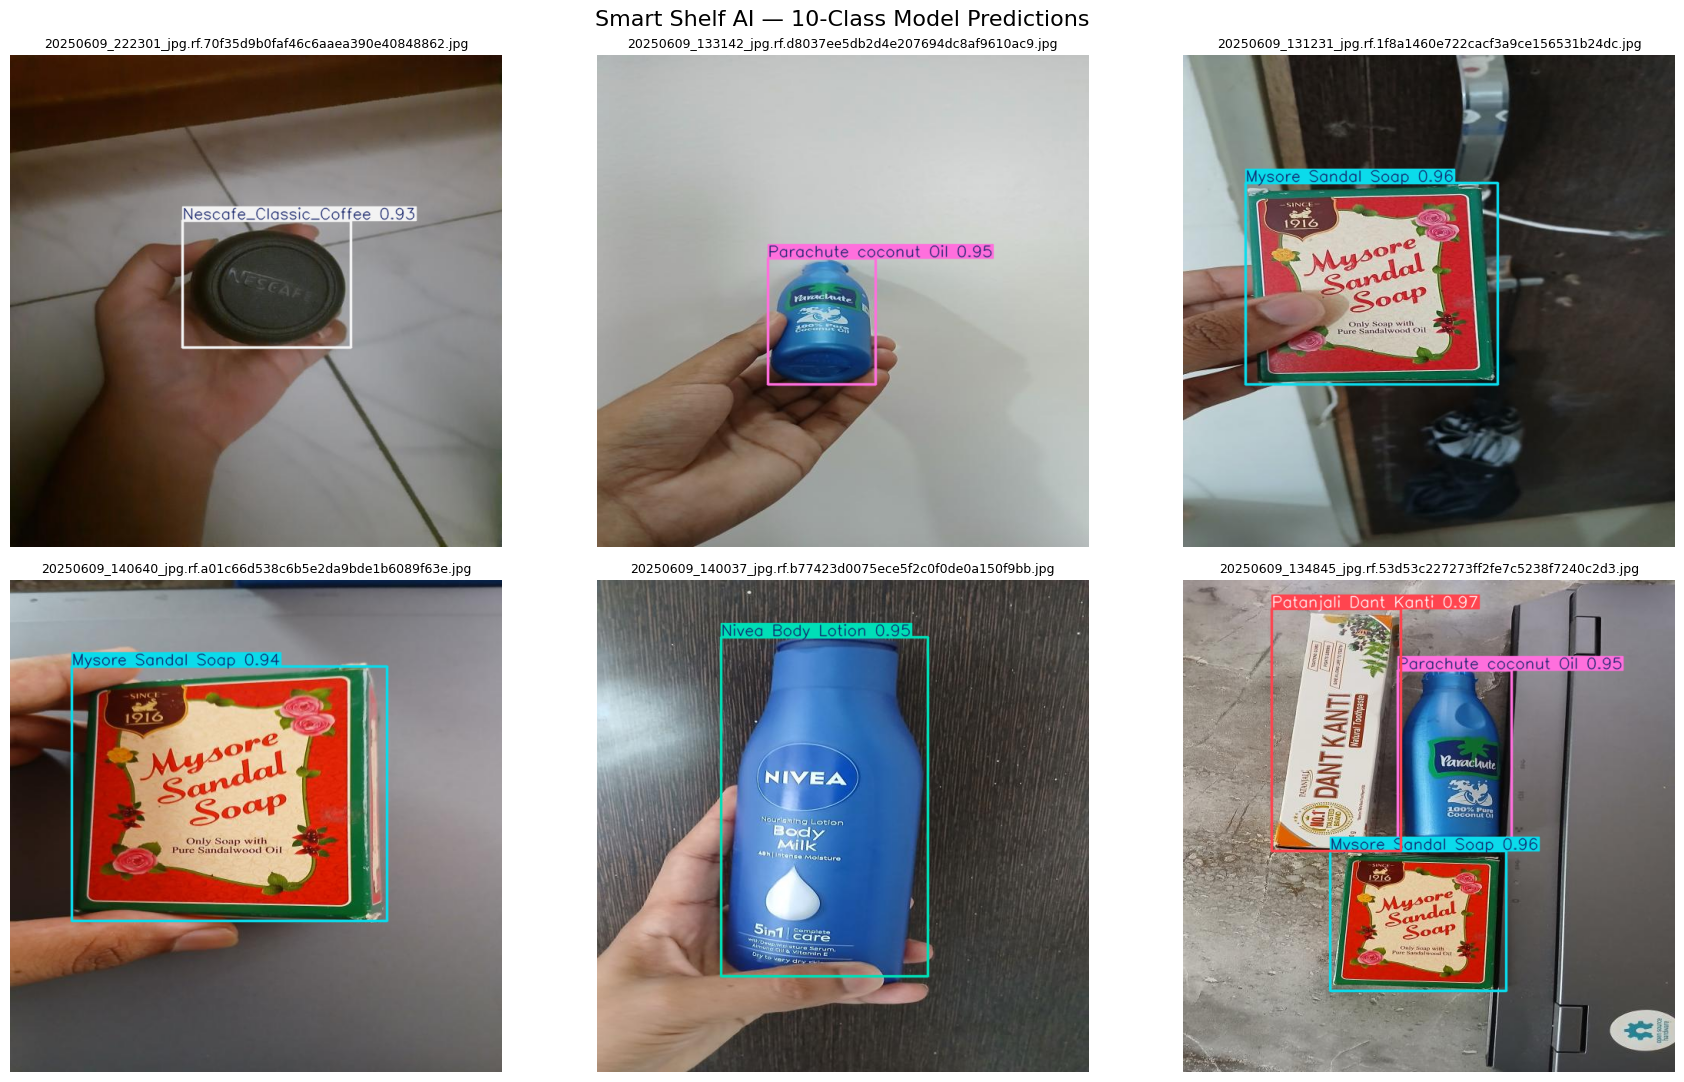

In [52]:

from pathlib import Path
import random
import yaml
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)

# Locate the newly trained 10-class checkpoint.
CHECKPOINT_10 = (
    DRIVE_ROOT / "runs" / "section8_indian_grocery_yolov8n_50epochs"
    / "weights" / "best.pt"
)

if not CHECKPOINT_10.exists():
    raise FileNotFoundError(
        f"10-class checkpoint not found: {CHECKPOINT_10}\n"
        "Update CHECKPOINT_10 to the actual best.pt path from Section 8A."
    )

# Use the dataset YAML already defined in Section 8.
# If your notebook uses a different variable, update this assignment.
DATA_YAML_10 = Path(str(DATA_10CLASS))

with DATA_YAML_10.open("r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

dataset_root = Path(data_config.get("path", DATA_YAML_10.parent))
if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML_10.parent / dataset_root).resolve()

val_entry = Path(str(data_config["val"]))
if not val_entry.is_absolute():
    val_entry = dataset_root / val_entry

# Support either a directory of images or a text file listing image paths.
if val_entry.is_file() and val_entry.suffix.lower() == ".txt":
    image_paths = []
    for line in val_entry.read_text().splitlines():
        line = line.strip()
        if line:
            p = Path(line)
            if not p.is_absolute():
                p = dataset_root / p
            if p.is_file():
                image_paths.append(p)
else:
    image_paths = [
        p for p in val_entry.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ] if val_entry.is_dir() else []

if not image_paths:
    raise FileNotFoundError(
        f"No validation images found at: {val_entry}\n"
        "Check the 'val' entry in your 10-class dataset YAML."
    )

random.seed(42)
selected_images = random.sample(image_paths, min(6, len(image_paths)))

model_10 = YOLO(str(CHECKPOINT_10))
device = 0 if torch.cuda.is_available() else "cpu"

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):
    result = model_10.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )[0]

    annotated = result.plot()
    ax.imshow(annotated[:, :, ::-1])
    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")

for ax in axes[len(selected_images):]:
    ax.axis("off")

plt.suptitle(
    "Smart Shelf AI — 10-Class Model Predictions",
    fontsize=16
)
plt.tight_layout()
plt.show()



## 9. Prepare the 9-Class YOLOv8 Training Experiment

This section prepares the configuration for the 9-class product detection experiment.

The dataset contains 79 training images, 23 validation images, and 11 test images. The model predicts nine product classes, excluding Nescafe from the original 10-class dataset.

Before training, we verify the dataset configuration, split directories, class count, and available GPU. The test split will be reserved for final evaluation.


In [32]:
# 9. PREPARE THE 9-CLASS YOLOv8 TRAINING EXPERIMENT

from pathlib import Path
import yaml
import torch

# Use the verified 9-class dataset configuration.
DATA_9CLASS = (
    DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
)

# Expected class mapping from the original notebook.
EXPECTED_CLASSES_9 = [
    "Bournvita",
    "Mysore Sandal Soap",
    "Nivea Body Lotion",
    "Nivea_Soft_Moisturising_cream",
    "Parachute coconut Oil",
    "Patanjali Dant Kanti",
    "Society_TeaPowder_plain",
    "Tresemme_Hairfall_Defense_conditioner",
    "Tresemme_Hairfall_Defense_shampoo",
]

if not DATA_9CLASS.is_file():
    raise FileNotFoundError(
        f"9-class dataset configuration not found: {DATA_9CLASS}"
    )

with DATA_9CLASS.open("r", encoding="utf-8") as file:
    config_9class = yaml.safe_load(file)

DATASET_ROOT_9 = Path(config_9class["path"])

# Verify split directories.
split_directories = {
    "train": DATASET_ROOT_9 / config_9class["train"],
    "val": DATASET_ROOT_9 / config_9class["val"],
    "test": DATASET_ROOT_9 / config_9class["test"],
}

print("Dataset configuration:", DATA_9CLASS)
print("Dataset root:", DATASET_ROOT_9)

for split_name, split_path in split_directories.items():
    print(
        f"{split_name.capitalize()} directory exists:",
        split_path.is_dir(),
        "|",
        split_path
    )
    if not split_path.is_dir():
        raise FileNotFoundError(
            f"Missing {split_name} image directory: {split_path}"
        )

# Verify the class mapping.
configured_names = config_9class["names"]

if isinstance(configured_names, dict):
    configured_names = [
        configured_names[key]
        for key in sorted(configured_names, key=lambda key: int(key))
    ]

configured_names = list(configured_names)

print("\nConfigured class count:", len(configured_names))

if configured_names != EXPECTED_CLASSES_9:
    raise ValueError(
        "The configured 9-class mapping differs from the expected mapping. "
        "Review the YAML before training."
    )

print("Class mapping verified:")
for class_id, class_name in enumerate(configured_names):
    print(f"  {class_id}: {class_name}")

# Display the available compute device.
print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print(
        "WARNING: No CUDA GPU detected. Training on CPU may be very slow."
    )


Dataset configuration: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/data_9class.yaml
Dataset root: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8
Train directory exists: True | /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/train/images
Val directory exists: True | /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/valid/images
Test directory exists: True | /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/test/images

Configured class count: 9
Class mapping verified:
  0: Bournvita
  1: Mysore Sandal Soap
  2: Nivea Body Lotion
  3: Nivea_Soft_Moisturising_cream
  4: Parachute coconut Oil
  5: Patanjali Dant Kanti
  6: Society_TeaPowder_plain
  7: Tresemme_Hairfall_Defense_conditioner
  8: Tresemme_Hairfall_Defense_shampoo

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


### 10. Inspect Existing 9-Class Checkpoints

Before training a new model, inspect the existing checkpoints and experiment directories. This prevents accidentally overwriting the current deployment model and helps us distinguish the new training results from historical results.

In [33]:
# 10. INSPECT EXISTING 9-CLASS CHECKPOINTS

from pathlib import Path
import hashlib

checkpoint_paths = [
    DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt",
    PROJECT_ROOT / "app" / "yolov8n_9class_v3_best.pt",
    DRIVE_DATA_ROOT / "yolov8_product_detection_9class.pt",
]

def sha256_file(file_path):
    digest = hashlib.sha256()
    with file_path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("Existing 9-class checkpoints:\n")

for checkpoint in checkpoint_paths:
    if checkpoint.is_file():
        print(f"FOUND: {checkpoint}")
        print(f"  Size: {checkpoint.stat().st_size / (1024**2):.2f} MB")
        print(f"  SHA-256: {sha256_file(checkpoint)}")
    else:
        print(f"NOT FOUND: {checkpoint}")

print("\nExisting experiment directories:")

for directory in [
    PROJECT_ROOT / "runs",
    PROJECT_ROOT / "runs" / "detect",
    DRIVE_DATA_ROOT / "runs",
]:
    print(f"{directory}: {'EXISTS' if directory.is_dir() else 'not present'}")

Existing 9-class checkpoints:

FOUND: /content/drive/MyDrive/product-identification-correlation_data/yolov8n_9class_v3_best.pt
  Size: 6.21 MB
  SHA-256: 284dae420c51696b5a79f331006a3233db0748d0e19ad9cb42516002d11b5574
FOUND: /content/smart-shelf-ai/app/yolov8n_9class_v3_best.pt
  Size: 6.21 MB
  SHA-256: 284dae420c51696b5a79f331006a3233db0748d0e19ad9cb42516002d11b5574
FOUND: /content/drive/MyDrive/product-identification-correlation_data/yolov8_product_detection_9class.pt
  Size: 6.20 MB
  SHA-256: 9103869d633452859a55c9eda2d5505f2a7f6f89e581c410d35d31227da4b3d1

Existing experiment directories:
/content/smart-shelf-ai/runs: EXISTS
/content/smart-shelf-ai/runs/detect: EXISTS
/content/drive/MyDrive/product-identification-correlation_data/runs: EXISTS


### 11. Train YOLOv8 on the 9-Class Dataset

Train a YOLOv8 Nano detector using the verified 9-class dataset and Tesla T4 GPU. Use 60 epochs, image size 640, and batch size 8. Save the experiment separately from the existing deployment checkpoint so the current model is not overwritten.

The training run will produce a new `best.pt` checkpoint and training metrics for later evaluation.

In [34]:
# 11. TRAIN THE 9-CLASS YOLOv8 MODEL

from pathlib import Path
import torch
import yaml
from ultralytics import YOLO

# ---------- Configuration ----------
DATA_9CLASS = (
    DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
)

PROJECT_RUNS = PROJECT_ROOT / "runs" / "detect"
EXPERIMENT_NAME = "smart_shelf_9class_60epochs"

EPOCHS = 60
IMAGE_SIZE = 640
BATCH_SIZE = 8
MODEL_BASE = "yolov8n.pt"

# ---------- Safety checks ----------
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Select a GPU runtime before training."
    )

if not DATA_9CLASS.is_file():
    raise FileNotFoundError(
        f"Dataset YAML not found: {DATA_9CLASS}"
    )

with DATA_9CLASS.open("r", encoding="utf-8") as f:
    train_config = yaml.safe_load(f)

if len(train_config["names"]) != 9:
    raise ValueError("Expected exactly 9 classes.")

experiment_dir = PROJECT_RUNS / EXPERIMENT_NAME

if experiment_dir.exists():
    raise FileExistsError(
        f"Experiment directory already exists: {experiment_dir}\n"
        "Choose a new EXPERIMENT_NAME rather than overwriting old results."
    )

PROJECT_RUNS.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset YAML:", DATA_9CLASS)
print("Base model:", MODEL_BASE)
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Experiment output:", experiment_dir)

# ---------- Training ----------
model = YOLO(MODEL_BASE)

results = model.train(
    data=str(DATA_9CLASS),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    pretrained=True,
    project=str(PROJECT_RUNS),
    name=EXPERIMENT_NAME,
    exist_ok=False,
    plots=True,
    save=True,
    seed=42,
)

# ---------- Verify outputs ----------
TRAINING_OUTPUT = experiment_dir
BEST_CHECKPOINT = TRAINING_OUTPUT / "weights" / "best.pt"
LAST_CHECKPOINT = TRAINING_OUTPUT / "weights" / "last.pt"

print("\nTraining finished.")
print("Best checkpoint exists:", BEST_CHECKPOINT.is_file())
print("Last checkpoint exists:", LAST_CHECKPOINT.is_file())
print("Training output:", TRAINING_OUTPUT)

if BEST_CHECKPOINT.is_file():
    print(
        "Best checkpoint size:",
        f"{BEST_CHECKPOINT.stat().st_size / (1024**2):.2f} MB"
    )
else:
    raise FileNotFoundError(
        "Training ended, but best.pt was not found. "
        "Inspect the training logs before proceeding."
    )

GPU: Tesla T4
Dataset YAML: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/data_9class.yaml
Base model: yolov8n.pt
Epochs: 60
Image size: 640
Batch size: 8
Experiment output: /content/smart-shelf-ai/runs/detect/smart_shelf_9class_60epochs
Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/data_9class.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0

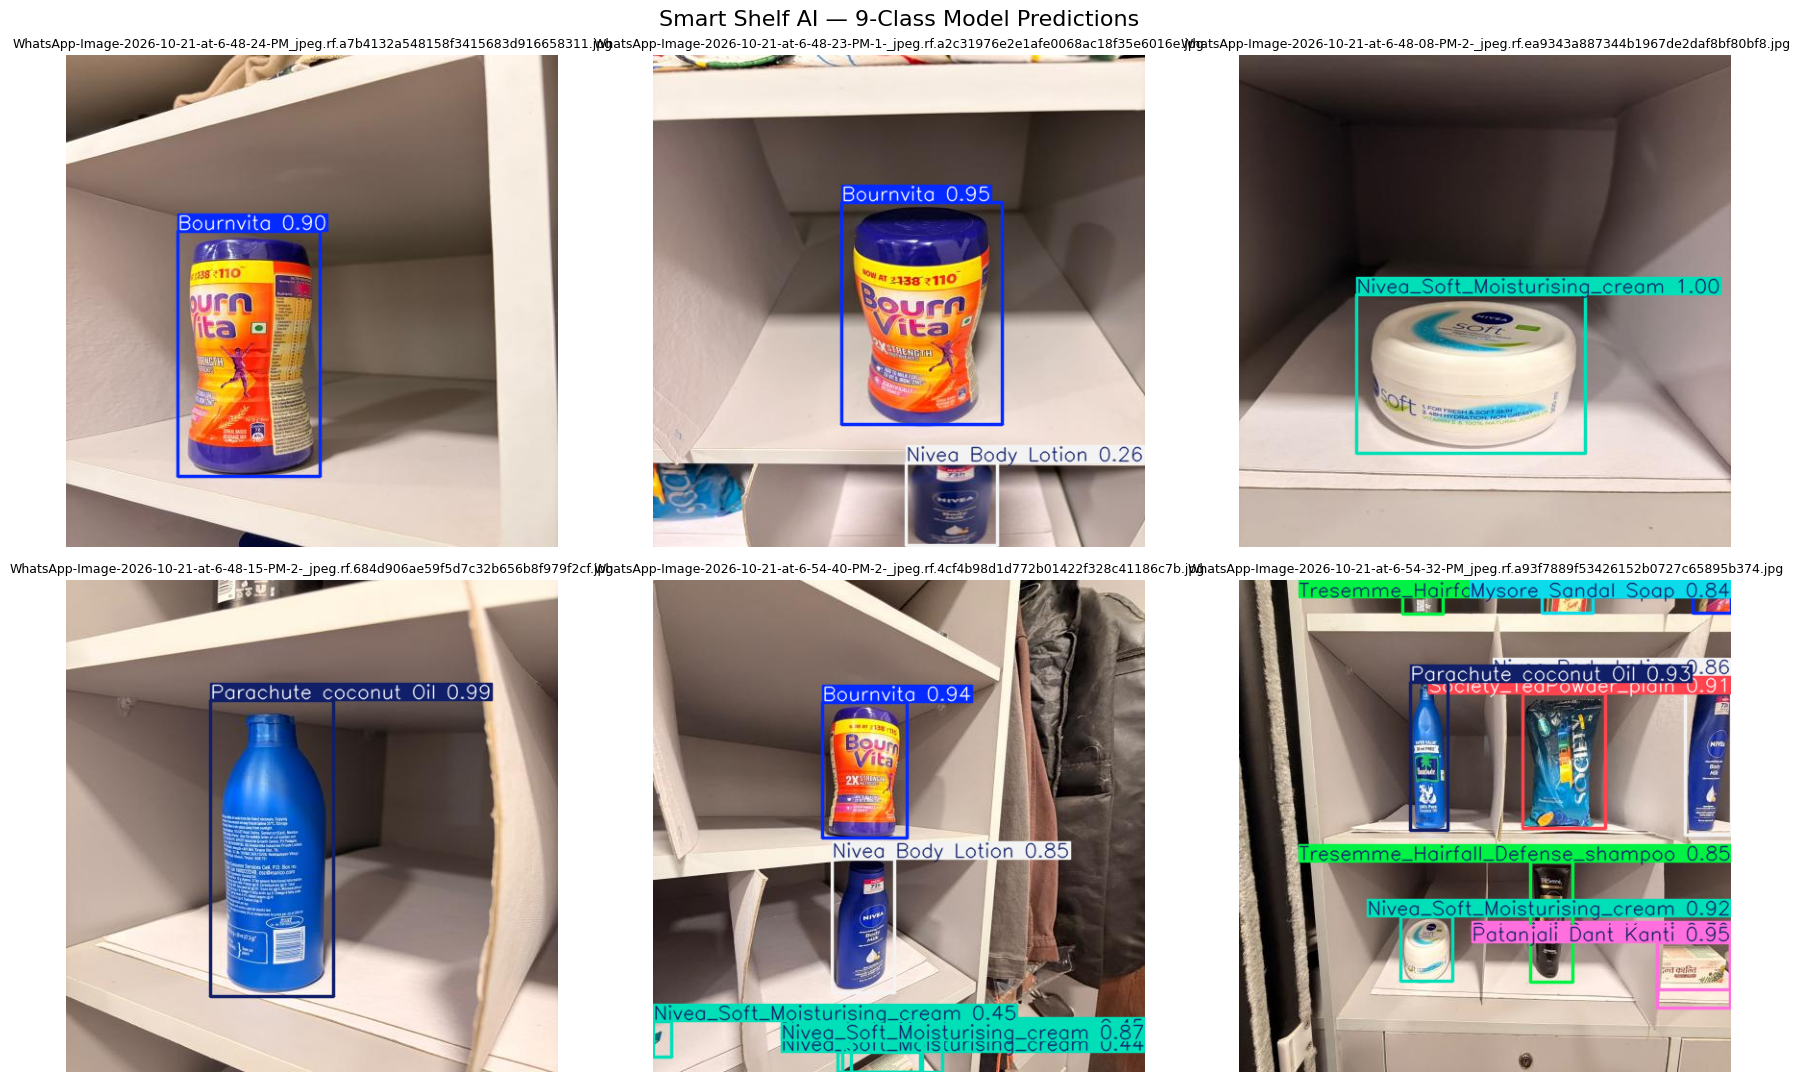

In [54]:

# 12. VISUALIZE THE 9-CLASS MODEL PREDICTIONS

import random
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

# Use the checkpoint created in Section 11
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Trained checkpoint not found: {BEST_CHECKPOINT}"
    )

# Read validation image directory from the dataset YAML
with DATA_9CLASS.open("r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config.get("path", DATA_9CLASS.parent))
if not dataset_root.is_absolute():
    dataset_root = (DATA_9CLASS.parent / dataset_root).resolve()

val_path = Path(str(config["val"]))
if not val_path.is_absolute():
    val_path = dataset_root / val_path

if val_path.is_file() and val_path.suffix.lower() == ".txt":
    val_images = []
    for line in val_path.read_text().splitlines():
        line = line.strip()
        if line:
            p = Path(line)
            if not p.is_absolute():
                p = dataset_root / p
            if p.is_file():
                val_images.append(p)
else:
    val_images = [
        p for p in val_path.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ] if val_path.is_dir() else []

if not val_images:
    raise FileNotFoundError(
        f"No validation images found at: {val_path}"
    )

random.seed(42)
selected_images = random.sample(val_images, min(6, len(val_images)))

visual_model = YOLO(str(BEST_CHECKPOINT))
device = 0 if torch.cuda.is_available() else "cpu"

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):
    prediction = visual_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )[0]

    annotated_image = prediction.plot()

    # Ultralytics returns BGR; Matplotlib expects RGB
    ax.imshow(annotated_image[:, :, ::-1])
    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")

for ax in axes[len(selected_images):]:
    ax.axis("off")

plt.suptitle(
    "Smart Shelf AI — 9-Class Model Predictions",
    fontsize=16
)
plt.tight_layout()
plt.show()


### 12. Save the Newly Trained Checkpoint

Copy the best checkpoint from the completed 60-epoch training run to Google Drive under a new filename. Keep the existing deployment checkpoint unchanged and verify the copied file using its SHA-256 hash.

In [35]:
# 12. BACK UP THE NEWLY TRAINED CHECKPOINT

from pathlib import Path
import shutil
import hashlib

TRAINING_OUTPUT = (
    PROJECT_ROOT / "runs" / "detect" /
    "smart_shelf_9class_60epochs"
)

BEST_CHECKPOINT = TRAINING_OUTPUT / "weights" / "best.pt"
LAST_CHECKPOINT = TRAINING_OUTPUT / "weights" / "last.pt"

DRIVE_CHECKPOINT_DIR = DRIVE_DATA_ROOT / "trained_checkpoints"
DRIVE_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

NEW_DRIVE_BEST = (
    DRIVE_CHECKPOINT_DIR / "smart_shelf_9class_60epochs_best.pt"
)
NEW_DRIVE_LAST = (
    DRIVE_CHECKPOINT_DIR / "smart_shelf_9class_60epochs_last.pt"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Missing best checkpoint: {BEST_CHECKPOINT}")

if not LAST_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Missing last checkpoint: {LAST_CHECKPOINT}")

# Refuse to overwrite a previous backup.
for destination in [NEW_DRIVE_BEST, NEW_DRIVE_LAST]:
    if destination.exists():
        raise FileExistsError(
            f"Backup already exists: {destination}. "
            "Inspect it before choosing a different filename."
        )

shutil.copy2(BEST_CHECKPOINT, NEW_DRIVE_BEST)
shutil.copy2(LAST_CHECKPOINT, NEW_DRIVE_LAST)

print("Best checkpoint copied:", NEW_DRIVE_BEST)
print("Last checkpoint copied:", NEW_DRIVE_LAST)

print("\nIntegrity verification:")
for source, destination in [
    (BEST_CHECKPOINT, NEW_DRIVE_BEST),
    (LAST_CHECKPOINT, NEW_DRIVE_LAST),
]:
    source_hash = sha256_file(source)
    destination_hash = sha256_file(destination)

    print(f"\n{destination.name}")
    print("Source SHA-256:     ", source_hash)
    print("Drive SHA-256:      ", destination_hash)
    print("Hashes match:       ", source_hash == destination_hash)

    if source_hash != destination_hash:
        raise RuntimeError(f"Checkpoint verification failed: {destination}")

Best checkpoint copied: /content/drive/MyDrive/product-identification-correlation_data/trained_checkpoints/smart_shelf_9class_60epochs_best.pt
Last checkpoint copied: /content/drive/MyDrive/product-identification-correlation_data/trained_checkpoints/smart_shelf_9class_60epochs_last.pt

Integrity verification:

smart_shelf_9class_60epochs_best.pt
Source SHA-256:      16322f0223fc402133d719ce7d467043a2c7d3d9dc32abd36786c8d9a2fd4ddd
Drive SHA-256:       16322f0223fc402133d719ce7d467043a2c7d3d9dc32abd36786c8d9a2fd4ddd
Hashes match:        True

smart_shelf_9class_60epochs_last.pt
Source SHA-256:      1ad3b92b1f088c6efccfaf7897e59a8575b9a03a6969632df647ea43d9771ca1
Drive SHA-256:       1ad3b92b1f088c6efccfaf7897e59a8575b9a03a6969632df647ea43d9771ca1
Hashes match:        True


### 13. Evaluate the Newly Trained Model on the Test Set

Evaluate the best checkpoint from the 60-epoch training run on the independent 9-class test split. Record precision, recall, mAP@50, and mAP@50–95. These results will be kept separate from the validation metrics and used for subsequent model comparisons.

In [36]:
# 13. EVALUATE THE NEW MODEL ON THE HELD-OUT TEST SET

from pathlib import Path
import yaml
import torch
from ultralytics import YOLO

DATA_9CLASS = (
    DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
)

BEST_CHECKPOINT = (
    DRIVE_DATA_ROOT / "trained_checkpoints" /
    "smart_shelf_9class_60epochs_best.pt"
)

if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Trained checkpoint not found: {BEST_CHECKPOINT}"
    )

with DATA_9CLASS.open("r", encoding="utf-8") as f:
    test_config = yaml.safe_load(f)

dataset_root = Path(test_config["path"])
test_images = dataset_root / test_config["test"]
test_labels = dataset_root / "test" / "labels"

if not test_images.is_dir():
    raise FileNotFoundError(f"Test images not found: {test_images}")

if not test_labels.is_dir():
    raise FileNotFoundError(f"Test labels not found: {test_labels}")

print("Checkpoint:", BEST_CHECKPOINT)
print("Test images:", test_images)
print("Test labels:", test_labels)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO(str(BEST_CHECKPOINT))

test_results = model.val(
    data=str(DATA_9CLASS),
    split="test",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True,
    project=str(PROJECT_ROOT / "runs" / "detect"),
    name="smart_shelf_9class_test_evaluation",
    exist_ok=True,
)

metrics = test_results.results_dict

print("\nTEST-SET METRICS")
for key, value in metrics.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

print("\nEvaluation completed.")
print(
    "Results directory:",
    PROJECT_ROOT / "runs" / "detect" /
    "smart_shelf_9class_test_evaluation"
)

Checkpoint: /content/drive/MyDrive/product-identification-correlation_data/trained_checkpoints/smart_shelf_9class_60epochs_best.pt
Test images: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/test/images
Test labels: /content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/test/labels
GPU available: True
GPU: Tesla T4
Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.2 ms, read: 0.1±0.0 MB/s, size: 25.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/roboflow_v3_yolov8/test/labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1

### 14. Evaluate the Existing Checkpoint on the Same Test Set

Evaluate the previously deployed 9-class checkpoint using the same dataset configuration, test split, image size, batch size, and GPU settings as the newly trained model. Record the metrics separately so the two checkpoints can be compared under consistent conditions. Do not overwrite either checkpoint.

In [37]:
# 14. EVALUATE THE EXISTING CHECKPOINT ON THE SAME TEST SET

from pathlib import Path
import torch
from ultralytics import YOLO

DATA_9CLASS = (
    DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
)

EXISTING_CHECKPOINT = (
    DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"
)

if not EXISTING_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Existing checkpoint not found: {EXISTING_CHECKPOINT}"
    )

EXISTING_EVAL_DIR = (
    PROJECT_ROOT / "runs" / "detect" /
    "existing_9class_test_evaluation"
)

if EXISTING_EVAL_DIR.exists():
    raise FileExistsError(
        f"Evaluation directory already exists: {EXISTING_EVAL_DIR}. "
        "Choose a new output name to preserve prior results."
    )

existing_model = YOLO(str(EXISTING_CHECKPOINT))

existing_test_results = existing_model.val(
    data=str(DATA_9CLASS),
    split="test",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True,
    project=str(PROJECT_ROOT / "runs" / "detect"),
    name="existing_9class_test_evaluation",
    exist_ok=False,
)

existing_metrics = existing_test_results.results_dict

print("\nEXISTING CHECKPOINT — TEST METRICS")
for key, value in existing_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

print("\nExisting checkpoint:", EXISTING_CHECKPOINT)
print("Evaluation output:", EXISTING_EVAL_DIR)

Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 24.5±7.6 MB/s, size: 25.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1sIuCWAsoleoNgJFC2NKnXJxoiqIIlNX0/product-identification-correlation_data/roboflow_v3_yolov8/test/labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11 2.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.5it/s 0.6s
                   all         11         26      0.831      0.891      0.932      0.641
             Bournvita          1          1      0.951          1      0.995      0.895
    Mysore Sandal Soap          4          4      0.89

Visual Predictions — 113-image, 9-class model

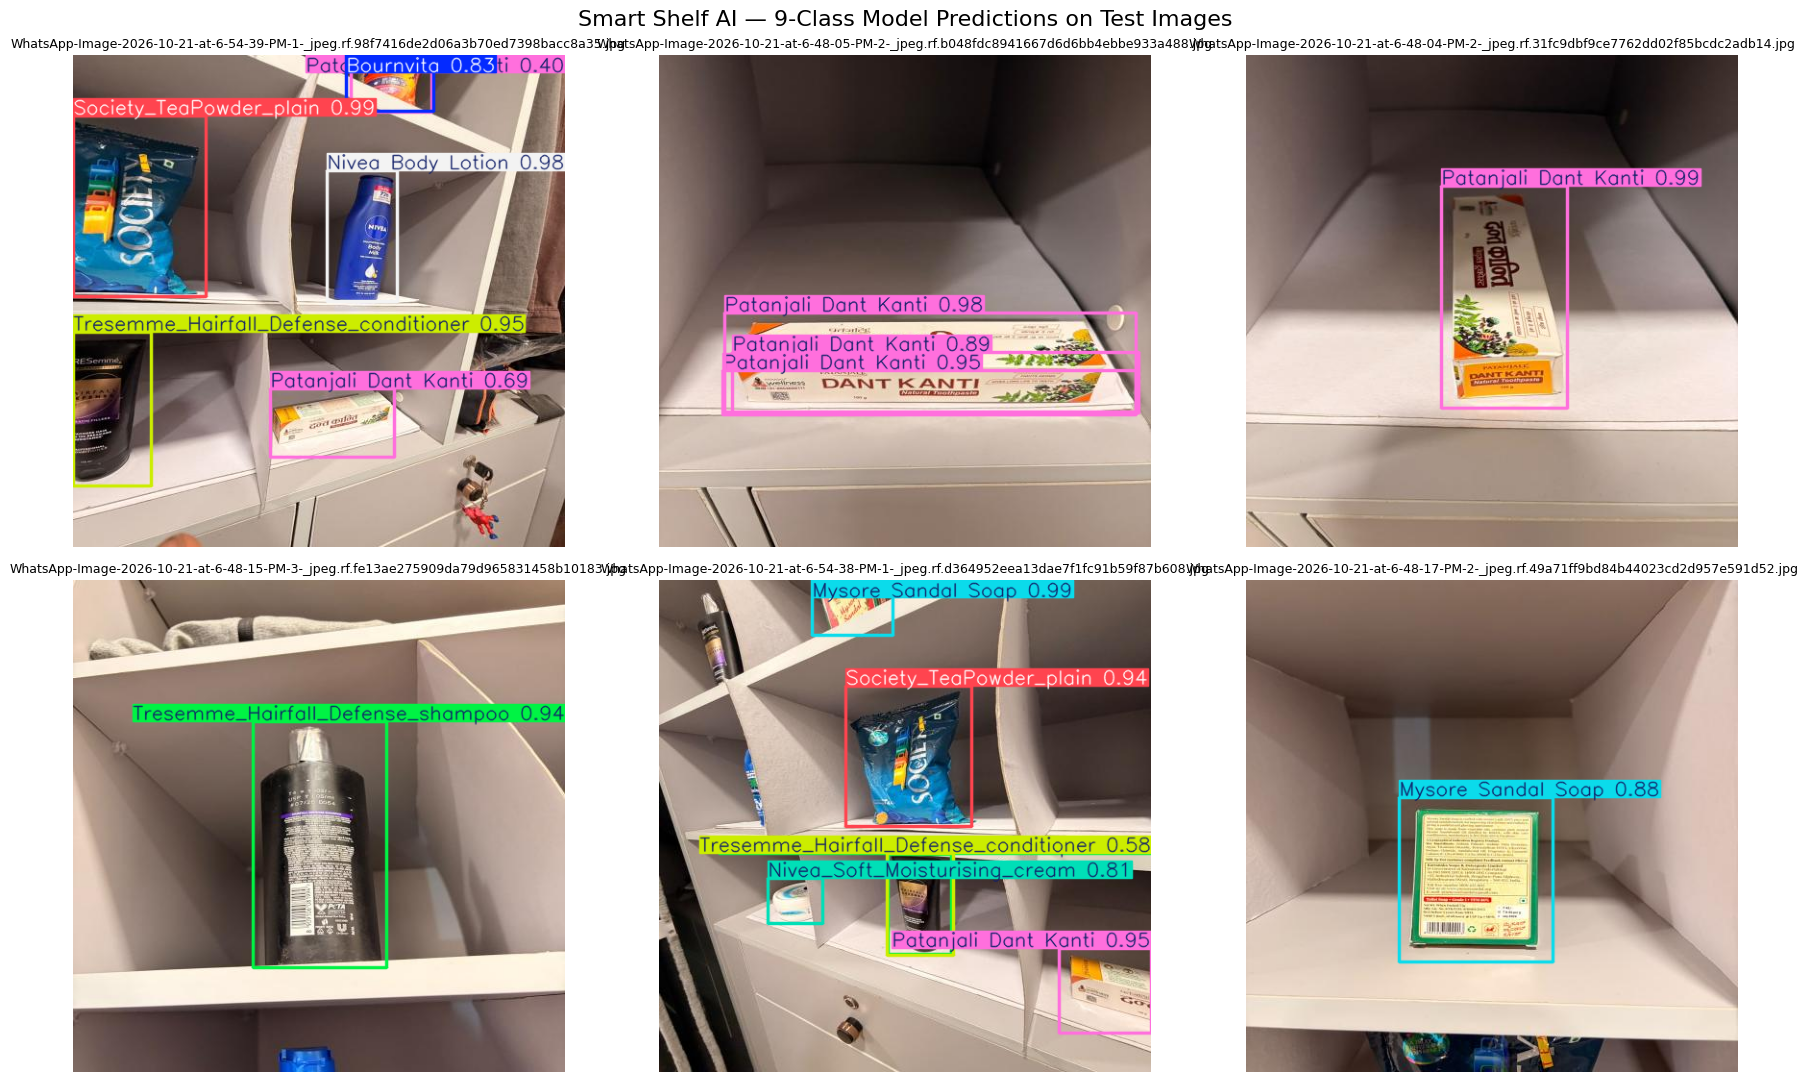

In [53]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)

CHECKPOINT_9 = DRIVE_ROOT / "yolov8n_9class_v3_best.pt"
TEST_IMAGES_9 = (
    DRIVE_ROOT / "roboflow_v3_yolov8" / "test" / "images"
)

if not CHECKPOINT_9.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_9}")

if not TEST_IMAGES_9.is_dir():
    raise FileNotFoundError(f"Test images directory not found: {TEST_IMAGES_9}")

test_images = sorted([
    p for p in TEST_IMAGES_9.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
])

if not test_images:
    raise FileNotFoundError(f"No test images found in {TEST_IMAGES_9}")

random.seed(42)
selected_images = random.sample(test_images, min(6, len(test_images)))

model_9 = YOLO(str(CHECKPOINT_9))
device = 0 if torch.cuda.is_available() else "cpu"

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):
    result = model_9.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )[0]

    annotated = result.plot()
    ax.imshow(annotated[:, :, ::-1])
    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")

for ax in axes[len(selected_images):]:
    ax.axis("off")

plt.suptitle(
    "Smart Shelf AI — 9-Class Model Predictions on Test Images",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [55]:

from ultralytics import YOLO

checkpoint_path = (
    "/content/drive/MyDrive/"
    "product-identification-correlation_data/"
    "yolov8n_9class_v3_best.pt"
)

model = YOLO(checkpoint_path)

print("Model task:", model.task)
print("Model names:", model.names)
print("Number of classes:", len(model.names))
print("Model architecture:", model.model.__class__.__name__)

ckpt = getattr(model, "ckpt", None)
if isinstance(ckpt, dict):
    print("\nAvailable checkpoint metadata:")
    for key in ("date", "version", "license", "train_args"):
        if key in ckpt:
            print(f"{key}: {ckpt[key]}")


Model task: detect
Model names: {0: 'Bournvita', 1: 'Mysore Sandal Soap', 2: 'Nivea Body Lotion', 3: 'Nivea_Soft_Moisturising_cream', 4: 'Parachute coconut Oil', 5: 'Patanjali Dant Kanti', 6: 'Society_TeaPowder_plain', 7: 'Tresemme_Hairfall_Defense_conditioner', 8: 'Tresemme_Hairfall_Defense_shampoo'}
Number of classes: 9
Model architecture: DetectionModel

Available checkpoint metadata:
date: 2026-10-21T20:58:13.717520+00:00
version: 8.4.183
license: AGPL-3.0 (https://ultralytics.com/license)
train_args: {'task': 'detect', 'mode': 'train', 'model': '/content/drive/MyDrive/product-identification-correlation_data/yolov8_product_detection_9class.pt', 'data': '/content/drive/MyDrive/product-identification-correlation_data/roboflow_v3_yolov8/data_9class.yaml', 'epochs': 60, 'time': None, 'patience': 15, 'batch': 8, 'imgsz': 640, 'save': True, 'save_period': -1, 'cache': False, 'device': '0', 'workers': 2, 'project': '/content/shelf_yolo_runs', 'name': 'yolov8n_9class_v3', 'exist_ok': True,

## 15. Test-Set Error Analysis

**Objective:** Analyse the predictions of the existing 9-class YOLOv8n checkpoint on the 11-image test set.

This section will:
- Compare predicted bounding boxes with ground-truth annotations using IoU ≥ 0.50.
- Count correct detections, wrong-class detections, missed objects, and extra predictions.
- Save per-image and per-detection error reports as CSV files.
- Save prediction visualisations for manual inspection.

The confidence threshold is fixed at 0.25 for this diagnostic. Results describe this small test set only.

Cell 15.1 — Generate error reports

In [48]:

from pathlib import Path
import yaml
import pandas as pd
import torch
from ultralytics import YOLO
from PIL import Image

DRIVE_DATA_ROOT = Path(
    "/content/drive/MyDrive/product-identification-correlation_data"
)
PROJECT_ROOT = Path("/content/smart-shelf-ai")

DATA_9CLASS = DRIVE_DATA_ROOT / "roboflow_v3_yolov8" / "data_9class.yaml"
CHECKPOINT = DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"

# Explicit output directory; create it if it doesn't exist.
ERROR_DIR = PROJECT_ROOT / "results" / "section15_test_error_analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

with DATA_9CLASS.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

root = Path(cfg.get("path", DATA_9CLASS.parent))
if not root.is_absolute():
    root = (DATA_9CLASS.parent / root).resolve()

test_entry = Path(cfg["test"])
test_base = test_entry if test_entry.is_absolute() else root / test_entry

if (test_base / "images").is_dir():
    images_dir = test_base / "images"
    labels_dir = test_base / "labels"
else:
    images_dir = test_base
    labels_dir = test_base.parent / "labels"

assert images_dir.is_dir(), f"Missing images: {images_dir}"
assert labels_dir.is_dir(), f"Missing labels: {labels_dir}"
assert CHECKPOINT.is_file(), f"Missing checkpoint: {CHECKPOINT}"

model = YOLO(str(CHECKPOINT))
names = model.names
device = 0 if torch.cuda.is_available() else "cpu"

def iou_xyxy(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union else 0.0

image_rows, detection_rows = [], []

image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

for path in image_paths:
    with Image.open(path) as im:
        width, height = im.size

    gt_boxes, gt_classes = [], []
    label_path = labels_dir / f"{path.stem}.txt"

    if label_path.is_file():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            cls, xc, yc, w, h = map(float, parts)
            gt_boxes.append([
                (xc-w/2)*width, (yc-h/2)*height,
                (xc+w/2)*width, (yc+h/2)*height
            ])
            gt_classes.append(int(cls))

    result = model.predict(
        source=str(path), conf=0.25, iou=0.50,
        imgsz=640, device=device, verbose=False
    )[0]

    pred_boxes, pred_classes, pred_conf = [], [], []
    if result.boxes is not None and len(result.boxes):
        pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int).tolist()
        pred_conf = result.boxes.conf.cpu().numpy().tolist()

    # Greedy, one-to-one box matching by highest IoU.
    pairs = []
    for gi, gb in enumerate(gt_boxes):
        for pi, pb in enumerate(pred_boxes):
            overlap = iou_xyxy(gb, pb)
            if overlap >= 0.50:
                pairs.append((overlap, gi, pi))
    pairs.sort(reverse=True)

    used_gt, used_pred, matches = set(), set(), []
    for overlap, gi, pi in pairs:
        if gi not in used_gt and pi not in used_pred:
            used_gt.add(gi)
            used_pred.add(pi)
            matches.append((overlap, gi, pi))

    correct = wrong = 0

    for overlap, gi, pi in matches:
        gc, pc = gt_classes[gi], pred_classes[pi]
        status = "correct_detection" if gc == pc else "wrong_class"
        correct += gc == pc
        wrong += gc != pc
        detection_rows.append({
            "image": path.name, "status": status,
            "gt_class": names[gc], "pred_class": names[pc],
            "confidence": round(float(pred_conf[pi]), 4),
            "IoU": round(float(overlap), 4)
        })

    missed = len(gt_boxes) - len(used_gt)
    extra = len(pred_boxes) - len(used_pred)

    for gi, gc in enumerate(gt_classes):
        if gi not in used_gt:
            detection_rows.append({
                "image": path.name, "status": "missed_object",
                "gt_class": names[gc], "pred_class": None,
                "confidence": None, "IoU": None
            })

    for pi, pc in enumerate(pred_classes):
        if pi not in used_pred:
            detection_rows.append({
                "image": path.name, "status": "extra_prediction",
                "gt_class": None, "pred_class": names[pc],
                "confidence": round(float(pred_conf[pi]), 4),
                "IoU": None
            })

    image_rows.append({
        "image": path.name,
        "ground_truth_objects": len(gt_boxes),
        "predicted_objects": len(pred_boxes),
        "correct_detections": int(correct),
        "wrong_class_detections": int(wrong),
        "missed_objects": int(missed),
        "extra_predictions": int(extra)
    })

image_df = pd.DataFrame(image_rows)
detection_df = pd.DataFrame(detection_rows)

image_csv = ERROR_DIR / "per_image_error_analysis.csv"
detection_csv = ERROR_DIR / "per_detection_error_analysis.csv"

image_df.to_csv(image_csv, index=False)
detection_df.to_csv(detection_csv, index=False)

print("Test images analysed:", len(image_df))
print("Ground-truth objects:", int(image_df["ground_truth_objects"].sum()))
print("Correct detections:", int(image_df["correct_detections"].sum()))
print("Wrong-class detections:", int(image_df["wrong_class_detections"].sum()))
print("Missed objects:", int(image_df["missed_objects"].sum()))
print("Extra predictions:", int(image_df["extra_predictions"].sum()))

print("\nPer-image results:")
display(image_df)

print("\nSaved CSV files:")
print(image_csv)
print(detection_csv)


Test images analysed: 11
Ground-truth objects: 26
Correct detections: 21
Wrong-class detections: 1
Missed objects: 4
Extra predictions: 4

Per-image results:


,image,ground_truth_objects,predicted_objects,correct_detections,wrong_class_detections,missed_objects,extra_predictions
0,WhatsApp-Image-2026-10-21-at-6-48-04-PM-2-_jpe...,1,1,1,0,0,0
1,WhatsApp-Image-2026-10-21-at-6-48-05-PM-2-_jpe...,1,2,1,0,0,1
2,WhatsApp-Image-2026-10-21-at-6-48-07-PM-1-_jpe...,1,1,1,0,0,0
3,WhatsApp-Image-2026-10-21-at-6-48-09-PM-3-_jpe...,1,1,1,0,0,0
4,WhatsApp-Image-2026-10-21-at-6-48-15-PM-3-_jpe...,1,1,1,0,0,0
5,WhatsApp-Image-2026-10-21-at-6-48-15-PM_jpeg.r...,1,1,1,0,0,0
6,WhatsApp-Image-2026-10-21-at-6-48-17-PM-2-_jpe...,1,1,1,0,0,0
7,WhatsApp-Image-2026-10-21-at-6-54-35-PM-1-_jpe...,4,3,3,0,1,0
8,WhatsApp-Image-2026-10-21-at-6-54-36-PM-1-_jpe...,4,3,3,0,1,0
9,WhatsApp-Image-2026-10-21-at-6-54-38-PM-1-_jpe...,7,6,5,0,2,1



Saved CSV files:
/content/smart-shelf-ai/results/section15_test_error_analysis/per_image_error_analysis.csv
/content/smart-shelf-ai/results/section15_test_error_analysis/per_detection_error_analysis.csv


## 15.2. Class-wise Error Analysis

**Objective:** Summarize the test-set errors by product class to identify categories with missed detections, incorrect classifications, and extra predictions.

This analysis uses the detection-level CSV generated in Section 15.1. It does not retrain or modify the model.

In [49]:

import pandas as pd
from pathlib import Path

ERROR_DIR = (
    Path("/content/smart-shelf-ai")
    / "results"
    / "section15_test_error_analysis"
)

DETECTION_CSV = ERROR_DIR / "per_detection_error_analysis.csv"

if not DETECTION_CSV.is_file():
    raise FileNotFoundError(
        f"Run Section 15.1 first. Missing: {DETECTION_CSV}"
    )

detections_df = pd.read_csv(DETECTION_CSV)

# Count ground-truth errors by the actual product class.
ground_truth_errors = detections_df[
    detections_df["status"].isin(["wrong_class", "missed_object"])
].copy()

ground_truth_errors["class"] = ground_truth_errors["gt_class"]

gt_error_summary = (
    ground_truth_errors
    .groupby(["class", "status"])
    .size()
    .unstack(fill_value=0)
)

for col in ["wrong_class", "missed_object"]:
    if col not in gt_error_summary.columns:
        gt_error_summary[col] = 0

gt_error_summary = gt_error_summary.rename(columns={
    "wrong_class": "Wrong-class detections",
    "missed_object": "Missed objects"
})

# Count extra predictions by the class predicted by the model.
extra_summary = (
    detections_df[detections_df["status"] == "extra_prediction"]
    .groupby("pred_class")
    .size()
    .rename("Extra predictions")
)

extra_summary.index.name = "class"

class_summary = gt_error_summary.join(
    extra_summary, how="outer"
).fillna(0).astype(int)

class_summary = class_summary.sort_values(
    by=["Missed objects", "Wrong-class detections", "Extra predictions"],
    ascending=False
)

class_summary_path = ERROR_DIR / "classwise_error_summary.csv"
class_summary.to_csv(class_summary_path)

print("CLASS-WISE TEST ERROR SUMMARY")
display(class_summary)

print("\nSaved to:", class_summary_path)


CLASS-WISE TEST ERROR SUMMARY


,Missed objects,Wrong-class detections,Extra predictions
class,,,
Tresemme_Hairfall_Defense_shampoo,1,1,1
Patanjali Dant Kanti,1,0,2
Parachute coconut Oil,1,0,0
Society_TeaPowder_plain,1,0,0
Bournvita,0,0,1



Saved to: /content/smart-shelf-ai/results/section15_test_error_analysis/classwise_error_summary.csv


## 16. Visualize and Inspect Test-Set Errors

**Objective:** Visually inspect the existing 9-class YOLOv8n model's predictions on the test set. Compare predicted bounding boxes with ground-truth annotations to identify missed products, extra detections, and classification errors.

This section uses the existing checkpoint without retraining. A small sample of test images will be visualized for qualitative analysis.

Cell 16.1 — Display ground truth vs. predictions

In [45]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml
import torch
from ultralytics import YOLO
import random

# Reuse the existing 9-class checkpoint
EXISTING_CHECKPOINT = (
    DRIVE_DATA_ROOT / "yolov8n_9class_v3_best.pt"
)

if not EXISTING_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {EXISTING_CHECKPOINT}"
    )

model = YOLO(str(EXISTING_CHECKPOINT))
class_names = model.names

# Use a deterministic sample of at most 6 test images
image_paths = sorted(
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if not image_paths:
    raise RuntimeError("No test images were found.")

random.seed(42)
sample_paths = random.sample(image_paths, min(6, len(image_paths)))

CONF_THRESHOLD = 0.25
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def load_gt_boxes(label_path, width, height):
    boxes = []
    classes = []

    if not label_path.exists():
        return boxes, classes

    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        cls, xc, yc, w, h = map(float, parts)

        x1 = (xc - w / 2) * width
        y1 = (yc - h / 2) * height
        x2 = (xc + w / 2) * width
        y2 = (yc + h / 2) * height

        boxes.append([x1, y1, x2, y2])
        classes.append(int(cls))

    return boxes, classes

for image_path in sample_paths:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    label_path = test_labels_dir / f"{image_path.stem}.txt"
    gt_boxes, gt_classes = load_gt_boxes(label_path, width, height)

    result = model.predict(
        source=str(image_path),
        conf=CONF_THRESHOLD,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )[0]

    pred_boxes, pred_classes, pred_confs = [], [], []

    if result.boxes is not None and len(result.boxes):
        pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int).tolist()
        pred_confs = result.boxes.conf.cpu().numpy().tolist()

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Left: ground truth
    axes[0].imshow(image)
    axes[0].set_title("Ground Truth")
    axes[0].axis("off")

    for box, cls in zip(gt_boxes, gt_classes):
        x1, y1, x2, y2 = box
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        axes[0].add_patch(rect)
        axes[0].text(
            x1, max(0, y1 - 5), class_names[cls],
            color="black", fontsize=8,
            bbox=dict(facecolor="lime", alpha=0.8, pad=2)
        )

    # Right: model predictions
    axes[1].imshow(image)
    axes[1].set_title(f"Predictions (confidence ≥ {CONF_THRESHOLD})")
    axes[1].axis("off")

    for box, cls, conf in zip(pred_boxes, pred_classes, pred_confs):
        x1, y1, x2, y2 = box
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        axes[1].add_patch(rect)
        axes[1].text(
            x1, max(0, y1 - 5),
            f"{class_names[cls]} {conf:.2f}",
            color="white", fontsize=8,
            bbox=dict(facecolor="red", alpha=0.8, pad=2)
        )

    fig.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()


Output hidden; open in https://colab.research.google.com to view.

## 17. Final Test Evaluation Summary

**Objective:** Consolidate the existing checkpoint's test metrics and the Section 15 error-analysis results into a single summary, with CSV outputs for reproducibility.

No model training is performed in this section.

In [50]:

from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path("/content/smart-shelf-ai")

ERROR_DIR = (
    PROJECT_ROOT
    / "results"
    / "section15_test_error_analysis"
)

IMAGE_CSV = ERROR_DIR / "per_image_error_analysis.csv"
DETECTION_CSV = ERROR_DIR / "per_detection_error_analysis.csv"
CLASSWISE_CSV = ERROR_DIR / "classwise_error_summary.csv"

# Confirm that all Section 15 outputs exist
required_files = [IMAGE_CSV, DETECTION_CSV, CLASSWISE_CSV]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required analysis output missing: {file_path}. "
            "Run the relevant Section 15 cell first."
        )

image_df = pd.read_csv(IMAGE_CSV)
detection_df = pd.read_csv(DETECTION_CSV)
classwise_df = pd.read_csv(CLASSWISE_CSV, index_col=0)

# Official metrics from the successful Section 14 evaluation.
# These values are from the output already recorded in the notebook.
test_metrics = {
    "precision": 0.8312,
    "recall": 0.8915,
    "mAP50": 0.9322,
    "mAP50_95": 0.6413,
    "test_images": 11,
    "ground_truth_objects": 26,
}

status_counts = detection_df["status"].value_counts().to_dict()

summary = {
    **test_metrics,
    "correct_detections": int(
        status_counts.get("correct_detection", 0)
    ),
    "wrong_class_detections": int(
        status_counts.get("wrong_class", 0)
    ),
    "missed_objects": int(
        status_counts.get("missed_object", 0)
    ),
    "extra_predictions": int(
        status_counts.get("extra_prediction", 0)
    ),
    "confidence_threshold": 0.25,
    "diagnostic_iou_threshold": 0.50,
}

# Display overall summary
summary_df = pd.DataFrame([summary])

print("FINAL 9-CLASS TEST EVALUATION SUMMARY")
display(summary_df)

print("\nPER-IMAGE ERROR ANALYSIS")
display(image_df)

print("\nCLASS-WISE ERROR ANALYSIS")
display(classwise_df)

# Save consolidated outputs
summary_csv = ERROR_DIR / "final_test_summary.csv"
summary_json = ERROR_DIR / "final_test_summary.json"

summary_df.to_csv(summary_csv, index=False)

with summary_json.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\nFinal summary saved:")
print(summary_csv)
print(summary_json)
print("\nAll input files were found and processed successfully.")


FINAL 9-CLASS TEST EVALUATION SUMMARY


,precision,recall,mAP50,mAP50_95,test_images,ground_truth_objects,correct_detections,wrong_class_detections,missed_objects,extra_predictions,confidence_threshold,diagnostic_iou_threshold
0,0.8312,0.8915,0.9322,0.6413,11,26,21,1,4,4,0.25,0.5



PER-IMAGE ERROR ANALYSIS


,image,ground_truth_objects,predicted_objects,correct_detections,wrong_class_detections,missed_objects,extra_predictions
0,WhatsApp-Image-2026-10-21-at-6-48-04-PM-2-_jpe...,1,1,1,0,0,0
1,WhatsApp-Image-2026-10-21-at-6-48-05-PM-2-_jpe...,1,2,1,0,0,1
2,WhatsApp-Image-2026-10-21-at-6-48-07-PM-1-_jpe...,1,1,1,0,0,0
3,WhatsApp-Image-2026-10-21-at-6-48-09-PM-3-_jpe...,1,1,1,0,0,0
4,WhatsApp-Image-2026-10-21-at-6-48-15-PM-3-_jpe...,1,1,1,0,0,0
5,WhatsApp-Image-2026-10-21-at-6-48-15-PM_jpeg.r...,1,1,1,0,0,0
6,WhatsApp-Image-2026-10-21-at-6-48-17-PM-2-_jpe...,1,1,1,0,0,0
7,WhatsApp-Image-2026-10-21-at-6-54-35-PM-1-_jpe...,4,3,3,0,1,0
8,WhatsApp-Image-2026-10-21-at-6-54-36-PM-1-_jpe...,4,3,3,0,1,0
9,WhatsApp-Image-2026-10-21-at-6-54-38-PM-1-_jpe...,7,6,5,0,2,1



CLASS-WISE ERROR ANALYSIS


,Missed objects,Wrong-class detections,Extra predictions
class,,,
Tresemme_Hairfall_Defense_shampoo,1,1,1
Patanjali Dant Kanti,1,0,2
Parachute coconut Oil,1,0,0
Society_TeaPowder_plain,1,0,0
Bournvita,0,0,1



Final summary saved:
/content/smart-shelf-ai/results/section15_test_error_analysis/final_test_summary.csv
/content/smart-shelf-ai/results/section15_test_error_analysis/final_test_summary.json

All input files were found and processed successfully.


Add a new Gradio section to your notebook

In [56]:
%pip install -q gradio ultralytics

In [58]:

# --------------------------------------------------
# 3. RUN BOTH MODELS AND COLLECT DETECTION DETAILS
# --------------------------------------------------

def get_detection_details(image, model):
    if image is None:
        return None, [], {}

    image = image.convert("RGB")
    result = model.predict(
        source=image,
        conf=CONFIDENCE_THRESHOLD,
        verbose=False
    )[0]

    annotated = Image.fromarray(result.plot()[..., ::-1])
    detections = []

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            xyxy = box.xyxy[0].cpu().numpy().tolist()

            detections.append({
                "Product": result.names[class_id],
                "Confidence": round(confidence * 100, 2),
                "Box": [round(v, 1) for v in xyxy]
            })

    counts = dict(Counter(d["Product"] for d in detections))
    return annotated, detections, counts


# --------------------------------------------------
# 4. COMPARE BOTH MODELS
# --------------------------------------------------

def compare_models(image):
    columns = [
        "Product",
        "Existing Count",
        "New Count",
        "Count Difference",
        "Existing Avg Confidence (%)",
        "New Avg Confidence (%)"
    ]

    if image is None:
        return None, None, pd.DataFrame(columns=columns), pd.DataFrame(), \
            "Upload an image to begin."

    old_image, old_detections, old_counts = get_detection_details(
        image, existing_model
    )
    new_image, new_detections, new_counts = get_detection_details(
        image, new_model
    )

    all_products = sorted(set(old_counts) | set(new_counts))
    comparison_rows = []

    for product in all_products:
        old_matches = [
            d for d in old_detections if d["Product"] == product
        ]
        new_matches = [
            d for d in new_detections if d["Product"] == product
        ]

        old_count = len(old_matches)
        new_count = len(new_matches)

        comparison_rows.append({
            "Product": product,
            "Existing Count": old_count,
            "New Count": new_count,
            "Count Difference": new_count - old_count,
            "Existing Avg Confidence (%)": (
                round(np.mean([d["Confidence"] for d in old_matches]), 2)
                if old_matches else None
            ),
            "New Avg Confidence (%)": (
                round(np.mean([d["Confidence"] for d in new_matches]), 2)
                if new_matches else None
            )
        })

    table = pd.DataFrame(comparison_rows, columns=columns)

    def make_detection_table(detections, model_name):
        if not detections:
            return pd.DataFrame(
                columns=["Model", "Product", "Confidence (%)", "Bounding Box"]
            )

        return pd.DataFrame([
            {
                "Model": model_name,
                "Product": d["Product"],
                "Confidence (%)": d["Confidence"],
                "Bounding Box": str(d["Box"])
            }
            for d in detections
        ])

    details = pd.concat([
        make_detection_table(old_detections, "Existing"),
        make_detection_table(new_detections, "New")
    ], ignore_index=True)

    summary = (
        f"Image size: {image.width} × {image.height}\n"
        f"Existing model: {len(old_detections)} detections, "
        f"{len(old_counts)} distinct product classes\n"
        f"New model: {len(new_detections)} detections, "
        f"{len(new_counts)} distinct product classes\n\n"
        "Confidence is the model's prediction score, not a guarantee "
        "that the detection is correct.\n"
        "Count Difference = New Count − Existing Count."
    )

    return old_image, new_image, table, details, summary


# --------------------------------------------------
# 5. CLEANER GRADIO INTERFACE
# --------------------------------------------------

with gr.Blocks(title="Smart Shelf AI | Product Detection") as demo:
    gr.Markdown("""
    # Smart Shelf AI
    ### Product Detection & Model Comparison

    Upload one image to compare both trained YOLO models on the same input.
    """)

    with gr.Row():
        with gr.Column():
            input_image = gr.Image(
                type="pil",
                label="Upload Product / Shelf Image"
            )
            compare_button = gr.Button(
                "Detect & Compare",
                variant="primary"
            )

    gr.Markdown("## Visual Comparison")

    with gr.Row(equal_height=True):
        with gr.Column():
            gr.Markdown("### Existing Model")
            existing_output = gr.Image(
                label="Existing Model Predictions",
                height=450,
                interactive=False
            )

        with gr.Column():
            gr.Markdown("### New Model")
            new_output = gr.Image(
                label="New Model Predictions",
                height=450,
                interactive=False
            )

    gr.Markdown("## Product-wise Comparison")

    comparison_table = gr.Dataframe(
        headers=[
            "Product",
            "Existing Count",
            "New Count",
            "Count Difference",
            "Existing Avg Confidence (%)",
            "New Avg Confidence (%)"
        ],
        label="Predicted Counts & Average Confidence",
        interactive=False,
        wrap=True
    )

    gr.Markdown("## Individual Detection Details")

    details_table = gr.Dataframe(
        label="One row per detected object",
        interactive=False,
        wrap=True
    )

    summary_output = gr.Textbox(
        label="Run Summary",
        lines=5,
        interactive=False
    )

    compare_button.click(
        fn=compare_models,
        inputs=[input_image],
        outputs=[
            existing_output,
            new_output,
            comparison_table,
            details_table,
            summary_output
        ]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f212032c2aa0cc214.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Whenever you want to use the demo
1. Open smartShelf.ipynb in Google Colab.
2. If the runtime is disconnected, reconnect it and run the Google Drive mount cell if necessary.
3. Run only your new Launch Gradio cell.
4. Open the new gradio.live link printed in the output.

In [64]:

# ============================================================
# SMART SHELF AI — GRADIO DEMO WITH DIAGNOSTIC PREDICTIONS
# Uses existing checkpoints. Does NOT retrain either model.
# ============================================================

from pathlib import Path
from collections import Counter

import gradio as gr
import pandas as pd
import numpy as np
from PIL import Image
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE IF REQUIRED
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. LOAD BOTH SAVED CHECKPOINTS
# ------------------------------------------------------------

EXISTING_CHECKPOINT = (
    "/content/drive/MyDrive/product-identification-correlation_data/"
    "yolov8n_9class_v3_best.pt"
)

NEW_CHECKPOINT = (
    "/content/drive/MyDrive/product-identification-correlation_data/"
    "trained_checkpoints/smart_shelf_9class_60epochs_best.pt"
)

for checkpoint in [EXISTING_CHECKPOINT, NEW_CHECKPOINT]:
    if not Path(checkpoint).exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")

existing_model = YOLO(EXISTING_CHECKPOINT)
new_model = YOLO(NEW_CHECKPOINT)

print("Both models loaded successfully.")
print("Existing:", EXISTING_CHECKPOINT)
print("New:", NEW_CHECKPOINT)

# Diagnostic threshold: temporarily lowered to reveal weak detections.
CONFIDENCE_THRESHOLD = 0.05

# ------------------------------------------------------------
# 3. RUN DETECTION AND PRINT DIAGNOSTICS
# ------------------------------------------------------------

def get_detection_details(image, model, model_label):
    if image is None:
        return None, [], {}

    image = image.convert("RGB")

    result = model.predict(
        source=image,
        conf=CONFIDENCE_THRESHOLD,
        verbose=False
    )[0]

    detections = []

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())

            detections.append({
                "Product": result.names[class_id],
                "Confidence": round(confidence * 100, 2),
                "Box": [
                    round(float(v), 1)
                    for v in box.xyxy[0].cpu().numpy()
                ]
            })

    # Diagnostic output appears in the Colab cell logs.
    print(f"\n--- {model_label} ---")
    print("Image size:", image.size)
    print("Detections:", len(detections))

    for detection in detections:
        print(
            f"{detection['Product']} | "
            f"Confidence: {detection['Confidence']:.2f}% | "
            f"Box: {detection['Box']}"
        )

    if not detections:
        print(
            "No detections at 0.05 confidence. "
            "The model may not recognize this image."
        )

    annotated = Image.fromarray(result.plot()[..., ::-1])
    counts = dict(Counter(d["Product"] for d in detections))

    return annotated, detections, counts

# ------------------------------------------------------------
# 4. COMPARE BOTH MODELS ON THE SAME IMAGE
# ------------------------------------------------------------

def compare_models(image):
    comparison_columns = [
        "Product",
        "Existing Count",
        "New Count",
        "Count Difference",
        "Existing Avg Confidence (%)",
        "New Avg Confidence (%)"
    ]

    detail_columns = [
        "Model", "Product", "Confidence (%)", "Bounding Box"
    ]

    if image is None:
        return (
            None,
            None,
            pd.DataFrame(columns=comparison_columns),
            pd.DataFrame(columns=detail_columns),
            "Please upload an image."
        )

    old_image, old_detections, old_counts = get_detection_details(
        image, existing_model, "EXISTING MODEL"
    )

    new_image, new_detections, new_counts = get_detection_details(
        image, new_model, "NEW MODEL"
    )

    # Product-wise counts and mean confidence.
    products = sorted(set(old_counts) | set(new_counts))
    comparison_rows = []

    for product in products:
        old_conf = [
            d["Confidence"] for d in old_detections
            if d["Product"] == product
        ]

        new_conf = [
            d["Confidence"] for d in new_detections
            if d["Product"] == product
        ]

        old_count = len(old_conf)
        new_count = len(new_conf)

        comparison_rows.append({
            "Product": product,
            "Existing Count": old_count,
            "New Count": new_count,
            "Count Difference": new_count - old_count,
            "Existing Avg Confidence (%)": (
                round(float(np.mean(old_conf)), 2)
                if old_conf else None
            ),
            "New Avg Confidence (%)": (
                round(float(np.mean(new_conf)), 2)
                if new_conf else None
            )
        })

    comparison_table = pd.DataFrame(
        comparison_rows,
        columns=comparison_columns
    )

    # Individual object detections.
    detail_rows = []

    for model_label, detections in [
        ("Existing", old_detections),
        ("New", new_detections)
    ]:
        for detection in detections:
            detail_rows.append({
                "Model": model_label,
                "Product": detection["Product"],
                "Confidence (%)": detection["Confidence"],
                "Bounding Box": str(detection["Box"])
            })

    details_table = pd.DataFrame(
        detail_rows,
        columns=detail_columns
    )

    summary = (
        f"Diagnostic confidence threshold: {CONFIDENCE_THRESHOLD:.2f}\n"
        f"Existing model detections: {len(old_detections)}\n"
        f"New model detections: {len(new_detections)}\n\n"
        "A lower threshold may reveal weak or incorrect predictions. "
        "Confidence scores are not guarantees of correctness."
    )

    return (
        old_image,
        new_image,
        comparison_table,
        details_table,
        summary
    )

# ------------------------------------------------------------
# 5. BUILD THE GRADIO INTERFACE
# ------------------------------------------------------------

with gr.Blocks(title="Smart Shelf AI | Diagnostic Comparison") as demo:
    gr.Markdown("""
    # Smart Shelf AI
    ### Product Detection & Model Comparison

    Upload an image to compare both YOLO models.
    Diagnostic mode uses a lower confidence threshold of 0.05.
    """)

    input_image = gr.Image(
        type="pil",
        label="Upload product / shelf image"
    )

    compare_button = gr.Button(
        "Detect & Compare",
        variant="primary"
    )

    gr.Markdown("## Visual Comparison")

    with gr.Row(equal_height=True):
        with gr.Column():
            gr.Markdown("### Existing Model")
            existing_output = gr.Image(
                label="Existing Model Predictions",
                height=450
            )

        with gr.Column():
            gr.Markdown("### New Model")
            new_output = gr.Image(
                label="New Model Predictions",
                height=450
            )

    gr.Markdown("## Product-wise Comparison")

    comparison_table = gr.Dataframe(
        headers=comparison_columns if False else [
            "Product", "Existing Count", "New Count",
            "Count Difference", "Existing Avg Confidence (%)",
            "New Avg Confidence (%)"
        ],
        label="Predicted Counts & Average Confidence",
        interactive=False,
        wrap=True
    )

    gr.Markdown("## Individual Detection Details")

    details_table = gr.Dataframe(
        label="Individual Predictions",
        interactive=False,
        wrap=True
    )

    summary_output = gr.Textbox(
        label="Diagnostic Summary",
        lines=4,
        interactive=False
    )

    compare_button.click(
        fn=compare_models,
        inputs=[input_image],
        outputs=[
            existing_output,
            new_output,
            comparison_table,
            details_table,
            summary_output
        ]
    )

# Stop the old Gradio cell before launching this one.
demo.launch(share=True, debug=True)


Both models loaded successfully.
Existing: /content/drive/MyDrive/product-identification-correlation_data/yolov8n_9class_v3_best.pt
New: /content/drive/MyDrive/product-identification-correlation_data/trained_checkpoints/smart_shelf_9class_60epochs_best.pt
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b8fdcbacc547373a9a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



--- EXISTING MODEL ---
Image size: (720, 1280)
Detections: 1
Parachute coconut Oil | Confidence: 6.26% | Box: [83.7, 6.6, 594.0, 1227.9]

--- NEW MODEL ---
Image size: (720, 1280)
Detections: 1
Parachute coconut Oil | Confidence: 17.90% | Box: [0.0, 0.0, 520.7, 1209.5]

--- EXISTING MODEL ---
Image size: (1200, 1600)
Detections: 19
Tresemme_Hairfall_Defense_shampoo | Confidence: 99.80% | Box: [525.1, 893.2, 634.0, 1170.0]
Nivea_Soft_Moisturising_cream | Confidence: 97.67% | Box: [107.4, 1061.5, 297.0, 1197.3]
Mysore Sandal Soap | Confidence: 97.28% | Box: [506.8, 417.7, 592.8, 472.8]
Nivea Body Lotion | Confidence: 95.72% | Box: [858.0, 564.6, 963.4, 775.7]
Tresemme_Hairfall_Defense_shampoo | Confidence: 94.29% | Box: [230.4, 343.6, 323.4, 480.4]
Patanjali Dant Kanti | Confidence: 93.41% | Box: [840.8, 1045.0, 1116.0, 1176.2]
Bournvita | Confidence: 84.03% | Box: [799.7, 336.1, 902.7, 475.0]
Parachute coconut Oil | Confidence: 76.93% | Box: [200.5, 585.6, 304.6, 800.5]
Mysore Sandal S

In [65]:

%cd /content/smart-shelf-ai

!git status
!git remote -v
!git branch --show-current
!git log -1 --oneline
!git ls-files


/content
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	indian_grocery_runtime.yaml
	results/section15_test_error_analysis/
	src/
	weights/
	yolov8n.pt

nothing added to commit but untracked files present (use "git add" to track)
origin	https://github.com/kasheeesh08/smart-shelf-ai.git (fetch)
origin	https://github.com/kasheeesh08/smart-shelf-ai.git (push)
main
702d25e (HEAD -> main, origin/main, origin/HEAD) Add Smart Shelf AI deployment and evaluation results
.gitignore
README.md
app/README.md
app/app.py
app/inference.py
app/requirements.txt
app/yolov8n_9class_v3_best.pt
requirements.txt
results/error_diagnostics.csv
results/model_comparison.csv
results/overall_metrics.csv
results/per_class_metrics.csv
results/per_image_metrics.csv


In [66]:

from pathlib import Path

project = Path("/content/smart-shelf-ai")

print("PROJECT DIRECTORY EXISTS:", project.exists())
print("\nUNTRACKED FOLDERS AND FILES:\n")

items = [
    "src",
    "weights",
    "results/section15_test_error_analysis",
    "indian_grocery_runtime.yaml",
    "yolov8n.pt",
]

for item in items:
    path = project / item
    print(f"\n--- {item} ---")

    if not path.exists():
        print("NOT FOUND")
        continue

    if path.is_file():
        print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")
    else:
        for file in sorted(path.rglob("*")):
            if file.is_file():
                size_mb = file.stat().st_size / (1024**2)
                print(f"{file.relative_to(project)} — {size_mb:.2f} MB")

print("\nNOTEBOOKS IN PROJECT:")
for notebook in project.rglob("*.ipynb"):
    if ".ipynb_checkpoints" not in str(notebook):
        print(notebook.relative_to(project))


PROJECT DIRECTORY EXISTS: True

UNTRACKED FOLDERS AND FILES:


--- src ---
src/inference.py — 0.00 MB

--- weights ---
weights/yolo26n.pt — 5.29 MB

--- results/section15_test_error_analysis ---
results/section15_test_error_analysis/classwise_error_summary.csv — 0.00 MB
results/section15_test_error_analysis/final_test_summary.csv — 0.00 MB
results/section15_test_error_analysis/final_test_summary.json — 0.00 MB
results/section15_test_error_analysis/per_detection_error_analysis.csv — 0.00 MB
results/section15_test_error_analysis/per_image_error_analysis.csv — 0.00 MB

--- indian_grocery_runtime.yaml ---
File size: 0.00 MB

--- yolov8n.pt ---
File size: 6.25 MB

NOTEBOOKS IN PROJECT:


In [67]:

from pathlib import Path

project = Path("/content/smart-shelf-ai")

files_to_check = [
    "app/app.py",
    "app/inference.py",
    "src/inference.py",
    "app/README.md",
    "README.md",
    ".gitignore",
]

for filename in files_to_check:
    path = project / filename
    print(f"\n{'=' * 60}\n{filename}")

    if path.exists() and path.is_file():
        try:
            content = path.read_text(errors="replace")
            for line_no, line in enumerate(content.splitlines(), 1):
                if any(word in line.lower() for word in [
                    "yolo", "checkpoint", "weights", ".pt",
                    "model_path", "best.pt"
                ]) or filename.endswith("README.md"):
                    print(f"{line_no}: {line[:200]}")
        except Exception as e:
            print("Could not read:", e)
    else:
        print("NOT FOUND")



app/app.py
46:     st.caption("Model: YOLOv8n · 9 product classes")

app/inference.py
7: from ultralytics import YOLO
9: MODEL_PATH = Path(__file__).parent / "yolov8n_9class_v3_best.pt"
25: model = YOLO(str(MODEL_PATH))

src/inference.py
7: from ultralytics import YOLO
9: MODEL_PATH = Path(__file__).parent / "yolov8n_9class_v3_best.pt"
25: model = YOLO(str(MODEL_PATH))

app/README.md
1: # Smart Shelf AI
2: 
3: Streamlit application for detecting and counting nine shelf product classes.
4: 
5: ## Run locally
6: Install dependencies with `pip install -r requirements.txt`, then run:
7: `streamlit run app.py`
8: 
9: The trained YOLO checkpoint must remain beside `inference.py`.

README.md
1: # Smart Shelf AI
2: 
3: Smart Shelf AI is a computer vision project for detecting and counting
4: nine product classes in shelf images. It uses a trained YOLOv8n model
5: and a Streamlit interface for image-based inference.
6: 
7: ## Features
8: 
9: - Upload a shelf image through the Streamlit applica

In [68]:

from pathlib import Path
import shutil

project = Path("/content/smart-shelf-ai")
drive = Path("/content/drive/MyDrive")

# 1. Find your saved notebook in Google Drive
matches = list(drive.rglob("smartShelf.ipynb"))

print("Notebook matches found:")
for p in matches:
    print(p)

if not matches:
    raise FileNotFoundError(
        "Could not find smartShelf.ipynb in Google Drive."
    )

# If multiple copies exist, stop so we don't copy the wrong one.
if len(matches) > 1:
    raise RuntimeError(
        "Multiple notebooks found. Check the paths printed above "
        "and choose the final notebook manually."
    )

# 2. Copy the notebook into the repository
notebooks_dir = project / "notebooks"
notebooks_dir.mkdir(parents=True, exist_ok=True)

notebook_destination = notebooks_dir / "smartShelf.ipynb"
shutil.copy2(matches[0], notebook_destination)
print("\nNotebook copied to:", notebook_destination)

# 3. Copy final evaluation summaries from Drive
drive_results = (
    drive / "product-identification-correlation_data"
    / "results" / "section15_test_error_analysis"
)
repo_results = project / "results" / "section15_test_error_analysis"
repo_results.mkdir(parents=True, exist_ok=True)

for filename in [
    "final_test_summary.csv",
    "final_test_summary.json",
    "classwise_error_summary.csv",
    "per_detection_error_analysis.csv",
    "per_image_error_analysis.csv",
]:
    source = drive_results / filename

    if source.exists():
        destination = repo_results / filename
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("Not found in Drive; skipped:", filename)

# 4. Review the changes — no Git commit or push yet
print("\n--- Git status ---")
import subprocess
subprocess.run(["git", "status", "--short"], cwd=project)


Notebook matches found:
/content/drive/MyDrive/Colab Notebooks/smartShelf.ipynb

Notebook copied to: /content/smart-shelf-ai/notebooks/smartShelf.ipynb
Copied: final_test_summary.csv
Copied: final_test_summary.json
Not found in Drive; skipped: classwise_error_summary.csv
Not found in Drive; skipped: per_detection_error_analysis.csv
Not found in Drive; skipped: per_image_error_analysis.csv

--- Git status ---


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [1]:

%cd /content/smart-shelf-ai

!git status --short
!git check-ignore -v notebooks/smartShelf.ipynb
!ls -lh notebooks/smartShelf.ipynb
!ls -lh results/section15_test_error_analysis/


[Errno 2] No such file or directory: '/content/smart-shelf-ai'
/content
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
ls: cannot access 'notebooks/smartShelf.ipynb': No such file or directory
ls: cannot access 'results/section15_test_error_analysis/': No such file or directory


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Drive mounted:", drive_root.exists())

for path in drive_root.rglob("smartShelf.ipynb"):
    print("Notebook found:", path)

Drive mounted: True
Notebook found: /content/drive/MyDrive/Colab Notebooks/smartShelf.ipynb


In [5]:
%cd /content
!git clone https://github.com/kasheeesh08/smart-shelf-ai.git

/content
Cloning into 'smart-shelf-ai'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 17 (delta 1), reused 17 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 5.63 MiB | 24.42 MiB/s, done.
Resolving deltas: 100% (1/1), done.
